# S³ semantic-axis comparison — k=10, seed 42

Uses the existing BGE-M3 embedding cache and saved k=10 scores. The charts compare topic-group score distributions across ten bipolar axes; the BERTopic names are grouping labels only. Dimension names are tentative readings of the endpoint keywords, not discovered discrete topics.

In [ ]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display
import matplotlib.pyplot as plt
from sentence_transformers import SentenceTransformer
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import CountVectorizer
from turftopic import SemanticSignalSeparation

project_root = Path.cwd().resolve()
if not (project_root / 'data/topic-analysis').exists():
    project_root = project_root.parent
if not (project_root / 'data/topic-analysis').exists():
    raise FileNotFoundError('Could not locate data/topic-analysis from the notebook working directory')
results = project_root / 'data/topic-analysis/results'
dataset_path = results / 'segment-dataset/all-segments.parquet'
embedding_path = results / 'jev-semantic-all/bubble-maps/segment-embeddings.npy'
embedding_manifest_path = results / 'jev-semantic-all/bubble-maps/embedding-manifest.json'
model_manifest_path = results / 'segment-dataset/manifest.json'
MODEL_ID = 'BAAI/bge-m3'
MODEL_REVISION = '5617a9f61b028005a4858fdac845db406aefb181'
N_COMPONENTS, RANDOM_STATE = 10, 42
print(f'Project: {project_root}')
print(f'Saved vectors: {embedding_path}')

In [ ]:
wanted = ['segment_key', 'segmentation', 'passage_id', 'episode_id', 'title', 'start_seconds', 'end_seconds', 'text', 'audio_url', 'topic_id', 'topic_name', 'membership_strength']
available = set(pd.read_parquet(dataset_path).columns)
all_passages = pd.read_parquet(dataset_path, columns=[c for c in wanted if c in available])
passages = all_passages.loc[all_passages.segmentation == 'semantic'].reset_index(drop=True)
embedding_manifest = json.loads(embedding_manifest_path.read_text(encoding='utf-8'))
model_info = json.loads(model_manifest_path.read_text(encoding='utf-8'))['models']['semantic']
embeddings = np.load(embedding_path, allow_pickle=False)
assert model_info['embedding_model_id'] == MODEL_ID
assert model_info['embedding_revision'] == MODEL_REVISION
assert int(model_info['embedding_dimension']) == 1024
assert passages.segment_key.tolist() == embedding_manifest['segment_keys'], 'Passage/vector order mismatch'
assert embeddings.shape == (len(passages), 1024), embeddings.shape
assert embeddings.dtype == np.float32 and np.isfinite(embeddings).all()
assert np.allclose(np.linalg.norm(embeddings, axis=1), 1.0, atol=1e-4), 'Vectors are not L2-normalized'
print(f'Validated {len(passages):,} passages × {embeddings.shape[1]} dimensions; float32, finite, L2-normalized.')
print(f"Model: {model_info['embedding_model_id']} @ {model_info['embedding_revision']}")
print(f"Original BERTopic outliers (topic -1): {(passages.topic_id == -1).sum():,}")

## Fit on the precomputed vectors

The encoder is loaded from local cache only. If that exact revision is not cached, the cell fails instead of downloading or substituting another model. Turftopic receives the corpus matrix directly via `embeddings=embeddings`.

In [ ]:
encoder = SentenceTransformer(MODEL_ID, revision=MODEL_REVISION, local_files_only=True)
s3 = SemanticSignalSeparation(n_components=N_COMPONENTS, encoder=encoder, vectorizer=CountVectorizer(max_features=500), random_state=RANDOM_STATE)
scores = s3.fit_transform(passages.text.tolist(), embeddings=embeddings)
assert scores.shape == (len(passages), N_COMPONENTS), scores.shape
assert np.isfinite(scores).all(), 'S³ scores contain non-finite values'
score_columns = [f's3_component_{i}' for i in range(N_COMPONENTS)]
scored_passages = passages.copy()
for i, column in enumerate(score_columns):
    scored_passages[column] = scores[:, i]
print(f'S³ fit passed: {len(passages):,} passages, {N_COMPONENTS} components, seed {RANDOM_STATE}.')
print('Passage vectors came from disk; no passage re-embedding was run.')

## S³ component summary and naming evidence

S³ returns continuous bipolar axes, not discrete topic assignments. The dominant-axis count below is only an exploratory tally: each passage is counted under the component with its largest absolute standardized score. It is not a cluster count or a calibrated classification. For naming, review Turftopic's high/low term lists alongside the positive/negative extreme passages below, then enter a human-reviewed bipolar label; no labels are generated automatically.

In [ ]:
score_frame = pd.DataFrame(scores, columns=score_columns)
score_std = score_frame.std(ddof=0).replace(0, 1)
score_z = (score_frame - score_frame.mean()) / score_std
dominant_component_index = np.abs(score_z.to_numpy()).argmax(axis=1)
dominant_counts = pd.Series(dominant_component_index).value_counts().reindex(range(N_COMPONENTS), fill_value=0)
positive_terms = s3.get_top_words(top_k=12, positive=True)
negative_terms = s3.get_top_words(top_k=12, positive=False)

component_stats = pd.DataFrame({
    'component_id': range(N_COMPONENTS),
    'passage_count': len(score_frame),
    'score_nan_count': score_frame.isna().sum().to_numpy(),
    'positive_score_count': score_frame.gt(0).sum().to_numpy(),
    'negative_score_count': score_frame.lt(0).sum().to_numpy(),
    'mean_score': score_frame.mean().to_numpy(),
    'score_std': score_frame.std(ddof=0).to_numpy(),
    'min_score': score_frame.min().to_numpy(),
    'max_score': score_frame.max().to_numpy(),
    'dominant_axis_passages_exploratory': dominant_counts.to_numpy(),
})
print(f'S³ passages scored: {len(score_frame):,}; missing passage texts: {passages.text.isna().sum():,}; blank passage texts: {(passages.text.notna() & passages.text.astype("string").str.strip().eq("")).sum():,}')
print('Continuous score distribution and exploratory dominant-axis counts (not topic membership)')
display(component_stats)

axis_review = pd.DataFrame({
    'component_id': range(N_COMPONENTS),
    'positive_end_terms': [', '.join(words) for words in positive_terms],
    'negative_end_terms': [', '.join(words) for words in negative_terms],
    'reviewed_bipolar_label': ['' for _ in range(N_COMPONENTS)],
    'review_notes': ['' for _ in range(N_COMPONENTS)],
})
print('Naming evidence: use both ends of each axis and verify them against the extreme passages in the next cell.')
display(axis_review)
assert int(component_stats.passage_count.iloc[0]) == len(passages)
assert int(component_stats.score_nan_count.sum()) == int(score_frame.isna().sum().sum())
assert int(component_stats.dominant_axis_passages_exploratory.sum()) == len(passages)
print(f"S3_COMPONENT_STATS_OK passages={len(passages):,}; components={N_COMPONENTS}; missing_scores={int(score_frame.isna().sum().sum())}")

## 2-D view of the S³ axes

Each panel shows the same passage map: a PCA projection of the already-saved embeddings. Color shows the signed standardized S³ score for that panel's axis; outlined points are original BERTopic outliers (`topic_id == -1`). The map is only a 2-D projection and does not define clusters or topics.

The table below gives one strongest positive and negative evidence passage per axis, alongside top terms. These are evidence for human review, not automatic topic names.

In [ ]:
projection = PCA(n_components=2, svd_solver='randomized', random_state=RANDOM_STATE).fit_transform(embeddings)
assert projection.shape == (len(passages), 2) and np.isfinite(projection).all()
projection_variance = PCA(n_components=2, svd_solver='randomized', random_state=RANDOM_STATE).fit(embeddings).explained_variance_ratio_.sum()
outlier_mask = passages.topic_id.eq(-1).to_numpy()
ncols = min(5, N_COMPONENTS)
nrows = (N_COMPONENTS + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 4 * nrows), sharex=True, sharey=True, constrained_layout=True)
axes = np.asarray(axes).reshape(-1)
for component_id, ax in enumerate(axes):
    if component_id >= N_COMPONENTS:
        ax.set_visible(False)
        continue
    values = score_z.iloc[:, component_id].to_numpy()
    ax.scatter(projection[:, 0], projection[:, 1], c=values, cmap='RdBu_r', vmin=-3, vmax=3, s=9, alpha=0.7, linewidths=0, rasterized=True)
    ax.scatter(projection[outlier_mask, 0], projection[outlier_mask, 1], facecolors='none', edgecolors='#222222', s=16, linewidths=0.45, alpha=0.7, rasterized=True)
    ax.set_title(f'Axis {component_id}')
    ax.set_xticks([]); ax.set_yticks([])
fig.supxlabel('PCA dimension 1'); fig.supylabel('PCA dimension 2')
fig.suptitle(f'S³ signed scores across the same 2-D embedding projection (PCA variance: {projection_variance:.1%})')
fig.colorbar(axes.flat[0].collections[0], ax=axes.ravel().tolist(), label='Standardized S³ score (colors clipped at ±3 SD)', shrink=0.78)
plt.show()

assert len(score_z.columns) == N_COMPONENTS
assert len(projection) == len(passages) == len(scored_passages)
assert int(outlier_mask.sum()) == int((passages.topic_id == -1).sum())
print(f'2-D projection uses the saved {embeddings.shape[1]}-D vectors for {len(passages):,} passages; BERTopic outliers outlined: {outlier_mask.sum():,}.')

table_rows = []
for component_id, score_column in enumerate(score_columns):
    positive = scored_passages[score_column].idxmax()
    negative = scored_passages[score_column].idxmin()
    pos = scored_passages.loc[positive]
    neg = scored_passages.loc[negative]
    table_rows.append({
        'axis': component_id,
        'positive terms': ', '.join(positive_terms[component_id][:8]),
        'positive passage': f"{pos.get('episode_id', '')} | {pos.get('title', '')} | {pos.get('start_seconds', '')}–{pos.get('end_seconds', '')}s | BERTopic {pos.get('topic_id', '')} | score {pos[score_column]:.3f} | {pos.get('text', '')}",
        'negative terms': ', '.join(negative_terms[component_id][:8]),
        'negative passage': f"{neg.get('episode_id', '')} | {neg.get('title', '')} | {neg.get('start_seconds', '')}–{neg.get('end_seconds', '')}s | BERTopic {neg.get('topic_id', '')} | score {neg[score_column]:.3f} | {neg.get('text', '')}",
    })
axis_evidence_table = pd.DataFrame(table_rows)
assert len(axis_evidence_table) == N_COMPONENTS
print('Strongest passage at each end of each component; use both poles and review the linked transcript/audio before naming an axis.')
display(axis_evidence_table)

In [ ]:
evidence_columns = [c for c in ['passage_id', 'episode_id', 'title', 'start_seconds', 'end_seconds', 'text', 'audio_url', 'topic_id', 'membership_strength'] if c in scored_passages.columns]
for i, score_column in enumerate(score_columns):
    print(f'Component {i}: highest-scoring passages')
    display(scored_passages.nlargest(3, score_column)[evidence_columns + [score_column]].reset_index(drop=True))
    print(f'Component {i}: lowest-scoring passages')
    display(scored_passages.nsmallest(3, score_column)[evidence_columns + [score_column]].reset_index(drop=True))
outliers = scored_passages.loc[scored_passages.topic_id == -1].copy()
outlier_view = outliers[evidence_columns + score_columns].sort_values(score_columns[0], key=lambda x: x.abs(), ascending=False)
print(f'Outliers shown for additional evidence review: {len(outliers):,} total; first 12 by absolute component-0 score.')
display(outlier_view.head(12).reset_index(drop=True))

High = above the 70th percentile; Low = below the 30th percentile among topic groups, ranked separately for each axis. Exact boundaries and the middle 40% are Typical. These are relative comparisons, not probabilities.
Percentile ranks compare topic-group means independently within each S³ axis.


axis_id,dimension_name,positive_end_keywords,negative_end_keywords
0,Work / time ↔ state / debate,"tööle, tööd, läks, töö, korraks, jooksul, minema, läinud, vahepeal, teame, äkki, valmis","riigi, arutelu, ees, parem, protsenti, riik, selles, võtame, kellel, üldiselt, hea, is"
1,Dialogue ↔ qualifiers / limits,"kelle, arutelu, kes, räägime, olin, arvan, oleme, teame, tere, teeme, tean, kellel","põhimõtteliselt, no, vähem, tähendab, lihtne, need, üldiselt, vähe, vähemalt, probleem, tihti, võimalik"
2,School / AI ↔ state / Europe,"koolis, ai, õpetaja, it, kooli, midagi, räägi, rääkima, teen, kuidagi, id, tööle","riik, ees, arust, oska, euroopa, hea, hoida, raske, eesti, sul, olukord, riigi"
3,Debate / reflection ↔ work / youth,"arutelu, mõtlema, raha, nõus, vähem, öelda, mõelda, ütles, ütleb, ütlesid, mõtlen, ütleme","teen, selles, noor, ees, eriti, kodus, it, koolis, kiiresti, eesti, teine, arust"
4,People / society ↔ money / work,"maailma, inimesed, inimeste, rääkida, sõna, olla, mõttes, kodus, ennast, rääkima, mõtlema, noored","raha, tööle, it, ega, ai, tööd, käib, kokku, selge, palju, id, töö"
5,Impact ↔ state,"hea, mõju, mind, inimese, mõtlema, tea, tee, aeg, mõttes, võime, ai, inimene","riigi, riik, euroopa, eest, eesti, kuhu, vot, eestis, olemas, oska, kellel, lapsed"
6,Education ↔ home,"õpetaja, koolis, eesmärk, ise, euroopa, maailma, riik, osa, mõtlema, mõelda, võime, oluline","väike, lahti, kodus, kinni, palun, juures, peale, laps, lapsed, puhul, probleem, asju"
7,School / work ↔ AI,"õpetaja, tööle, koolis, minema, töö, lapsed, hoida, hakkama, tööd, kooli, lähevad, rääkida","ai, it, maailma, vot, noh, arust, maailmas, et, aeg, nii, no, tekib"
8,School ↔ people,"koolis, kooli, teen, õpetaja, väike, mitu, teed, laps, elu, peaks, lapsed, talle","inimese, inimeste, inimene, inimest, euroopa, inimesi, head, inimesed, töö, vastu, ütleb, olen"
9,AI / state ↔ hedging,"ai, it, arvan, riik, kodus, kes, töö, sisse, siia, tööle, arust, eestis","mingisugune, mingisuguse, erinevaid, mõned, erinevad, erinevate, olid, juhul, mille, vähe, ütleks, olnud"


topic_name,passage_count,high_dimensions,low_dimensions,highest_dimension,highest_mean_z,highest_axis_positive_keywords,lowest_dimension,lowest_mean_z,lowest_axis_negative_keywords,axis_0_mean_z,axis_1_mean_z,axis_2_mean_z,axis_3_mean_z,axis_4_mean_z,axis_5_mean_z,axis_6_mean_z,axis_7_mean_z,axis_8_mean_z,axis_9_mean_z
AI abil teksti ja heli konverteerimine,9,"School / AI ↔ state / Europe, Education ↔ home, AI / state ↔ hedging","Debate / reflection ↔ work / youth, People / society ↔ money / work, School / work ↔ AI",School / AI ↔ state / Europe,0.933,"koolis, ai, õpetaja, it, kooli, midagi, räägi, rääkima, teen, kuidagi, id, tööle",People / society ↔ money / work,-1.342,"raha, tööle, it, ega, ai, tööd, käib, kokku, selge, palju, id, töö",0.077599,0.119909,0.933337,-1.260624,-1.342293,0.004040,0.596678,-0.817256,0.101654,0.764013
AI kasutamine töö- ja loometekstide koostamisel,7,"Dialogue ↔ qualifiers / limits, School / AI ↔ state / Europe, Impact ↔ state, AI / state ↔ hedging","People / society ↔ money / work, School / work ↔ AI, School ↔ people",School / AI ↔ state / Europe,1.799,"koolis, ai, õpetaja, it, kooli, midagi, räägi, rääkima, teen, kuidagi, id, tööle",School ↔ people,-1.113,"inimese, inimeste, inimene, inimest, euroopa, inimesi, head, inimesed, töö, vastu, ütleb, olen",0.299367,0.453193,1.798528,-0.359979,-0.884314,0.632823,-0.230222,-1.095567,-1.113179,0.415751
AI kasutamise reeglid ja hindamine ülikoolis,16,"School / AI ↔ state / Europe, Impact ↔ state, Education ↔ home","Work / time ↔ state / debate, Debate / reflection ↔ work / youth, School / work ↔ AI",School / AI ↔ state / Europe,1.683,"koolis, ai, õpetaja, it, kooli, midagi, räägi, rääkima, teen, kuidagi, id, tööle",School / work ↔ AI,-1.029,"ai, it, maailma, vot, noh, arust, maailmas, et, aeg, nii, no, tekib",-0.970688,-0.265396,1.682937,-0.674679,-0.442506,1.146055,1.195064,-1.028803,0.239503,-0.085050
AI muudab üksikettevõtluse lihtsamaks,6,"Work / time ↔ state / debate, Dialogue ↔ qualifiers / limits, School / AI ↔ state / Europe, AI / state ↔ hedging","Debate / reflection ↔ work / youth, People / society ↔ money / work, School / work ↔ AI, School ↔ people",School / AI ↔ state / Europe,1.202,"koolis, ai, õpetaja, it, kooli, midagi, räägi, rääkima, teen, kuidagi, id, tööle",People / society ↔ money / work,-1.494,"raha, tööle, it, ega, ai, tööd, käib, kokku, selge, palju, id, töö",0.670170,0.769723,1.202031,-0.926639,-1.494069,-0.061499,0.243661,-0.815025,-0.582319,0.910949
AI mõju töökorraldusele ja tööturule,8,"Work / time ↔ state / debate, School / AI ↔ state / Europe, Impact ↔ state, AI / state ↔ hedging","Dialogue ↔ qualifiers / limits, People / society ↔ money / work, School ↔ people",School / AI ↔ state / Europe,1.719,"koolis, ai, õpetaja, it, kooli, midagi, räägi, rääkima, teen, kuidagi, id, tööle",School ↔ people,-0.965,"inimese, inimeste, inimene, inimest, euroopa, inimesi, head, inimesed, töö, vastu, ütleb, olen",0.952567,-0.362557,1.718683,-0.241390,-0.933918,0.721995,0.380148,-0.194723,-0.965024,0.997467
AI odava kasutuselevõtu ja eksporti,13,"School / AI ↔ state / Europe, AI / state ↔ hedging","Dialogue ↔ qualifiers / limits, Debate / reflection ↔ work / youth, People / society ↔ money / work, School / work ↔ AI, School ↔ people",School / AI ↔ state / Europe,0.876,"koolis, ai, õpetaja, it, kooli, midagi, räägi, rääkima, teen, kuidagi, id, tööle",School / work ↔ AI,-1.379,"ai, it, maailma, vot, noh, arust, maailmas, et, aeg, nii, no, tekib",-0.064098,-0.509745,0.876210,-0.804561,-1.215102,0.358564,0.411517,-1.379126,-0.736190,0.518543
AI päringute energiakulu läbipaistvus,14,"Impact ↔ state, AI / state ↔ hedging","Dialogue ↔ qualifiers / limits, People / society ↔ money / work, School / work ↔ AI",Impact ↔ state,1.210,"hea, mõju, mind, inimese, mõtlema, tea, tee, aeg, mõttes, võime, ai, inimene",School / work ↔ AI,-1.981,"ai, it, maailma, vot, noh, arust, maailmas, et, aeg, nii, no, tekib",-0.332590,-0.409880,0.342143,-0.184210,-0.833458,1.21

topic_name,axis_id,dimension_name,mean_score,axis_percentile,status
"laste hambaravi, narkoos ja vanema vastutus",0,Work / time ↔ state / debate,-2.097454,0.004219,low
Laste piltide postitamine vanemate poolt,0,Work / time ↔ state / debate,-2.056449,0.008439,low
raviraha jaotamine patsiendiga kaasa,0,Work / time ↔ state / debate,-1.964683,0.012658,low
Terviseandmete kasutamine ravi ja ennetuse parandamiseks,0,Work / time ↔ state / debate,-1.949560,0.016878,low
Veebis lastega suhtlemise seksuaalriskid,0,Work / time ↔ state / debate,-1.722468,0.021097,low
Laste internetikäitumine ja abiotsimine,0,Work / time ↔ state / debate,-1.670656,0.025316,low
"Lasteaia kvaliteet, märkamise ja toetuse roll",0,Work / time ↔ state / debate,-1.579189,0.029536,low
andmejärelevalve ja tehisintellekti piirid,0,Work / time ↔ state / debate,-1.557614,0.033755,low
Haigekassa rahastusmudeli ümbermõtestamine,0,Work / time ↔ state / debate,-1.492451,0.037975,low
Interneti solvangute ja ähvarduste ohjeldamine,0,Work / time ↔ state / debate,-1.482833,0.042194,low


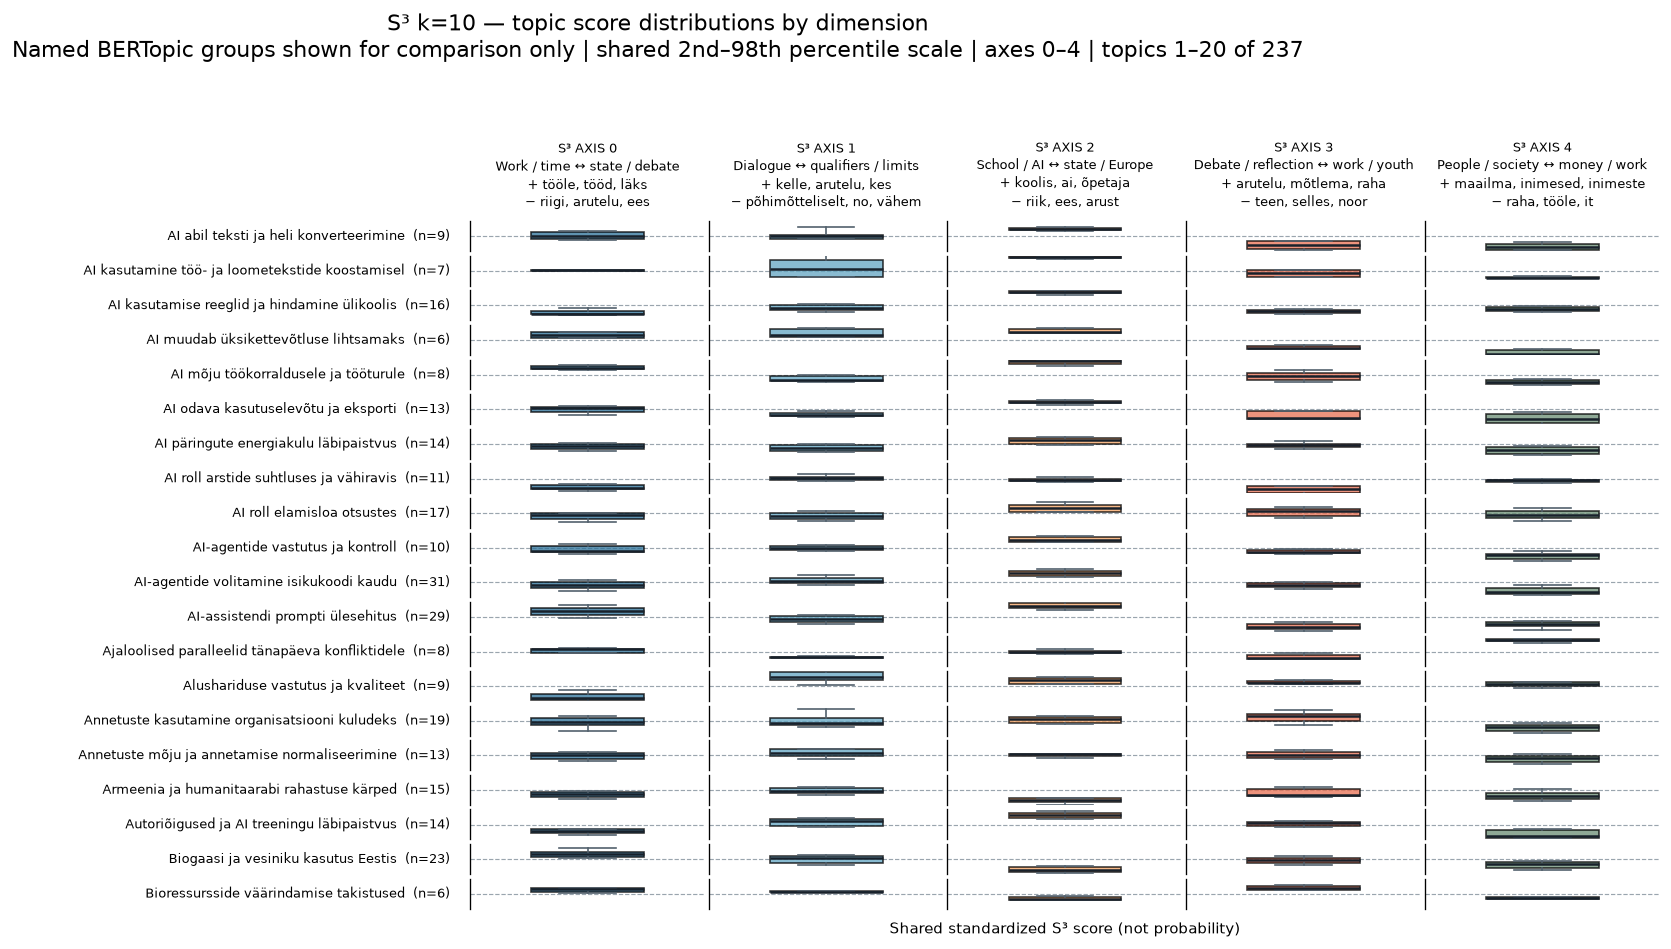

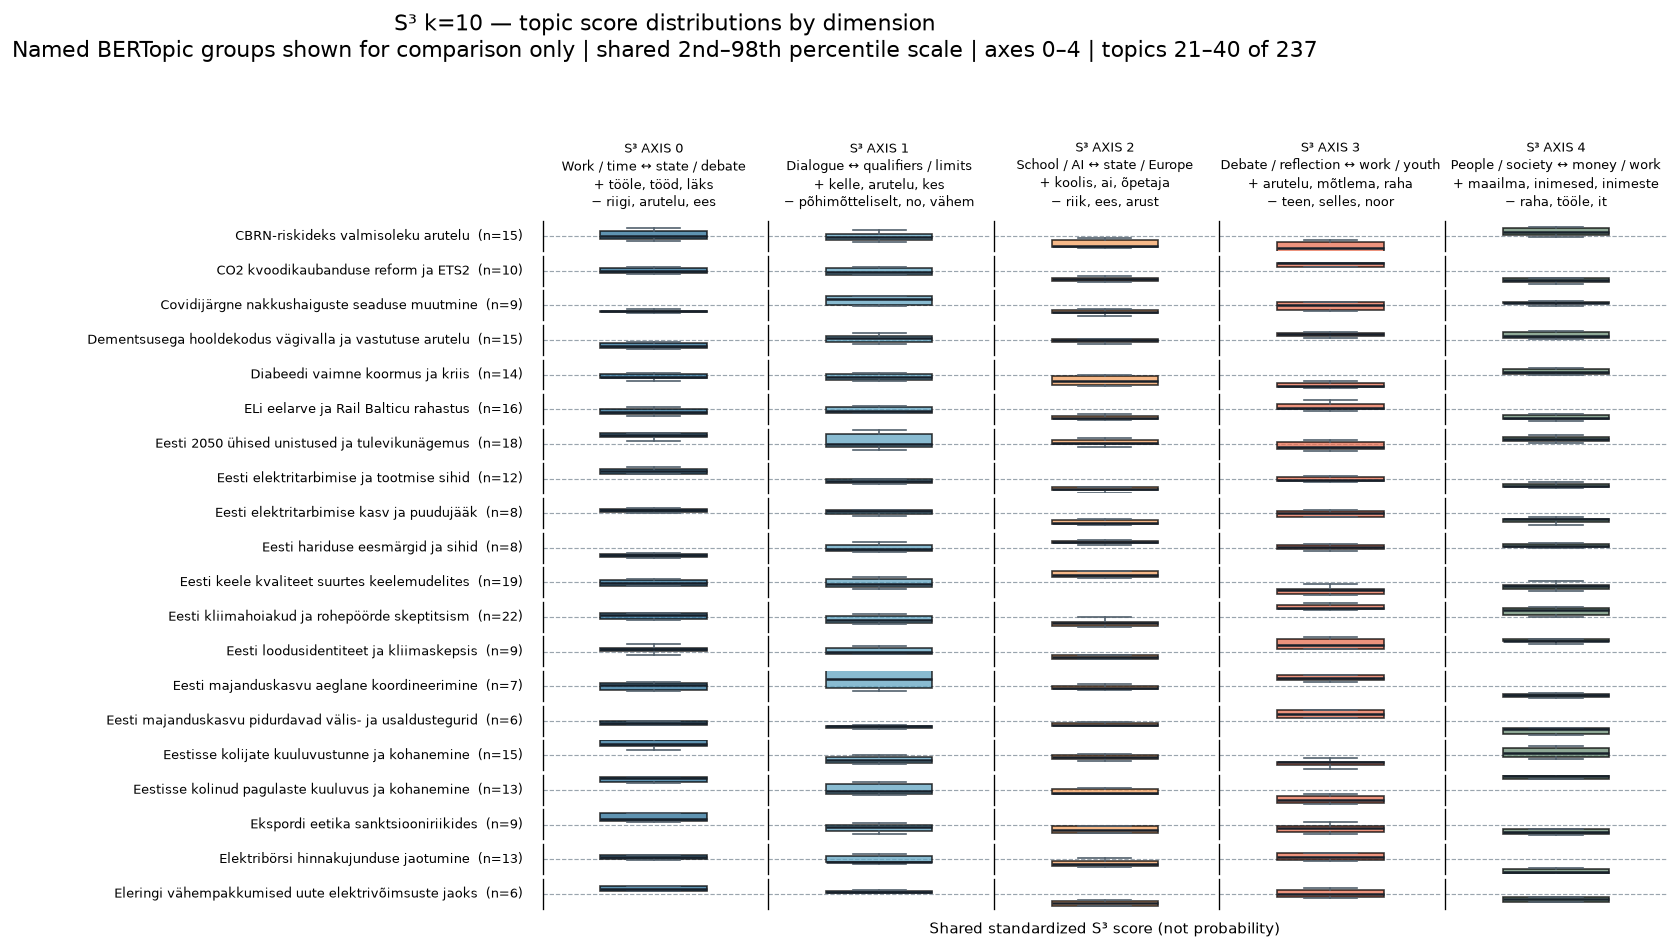

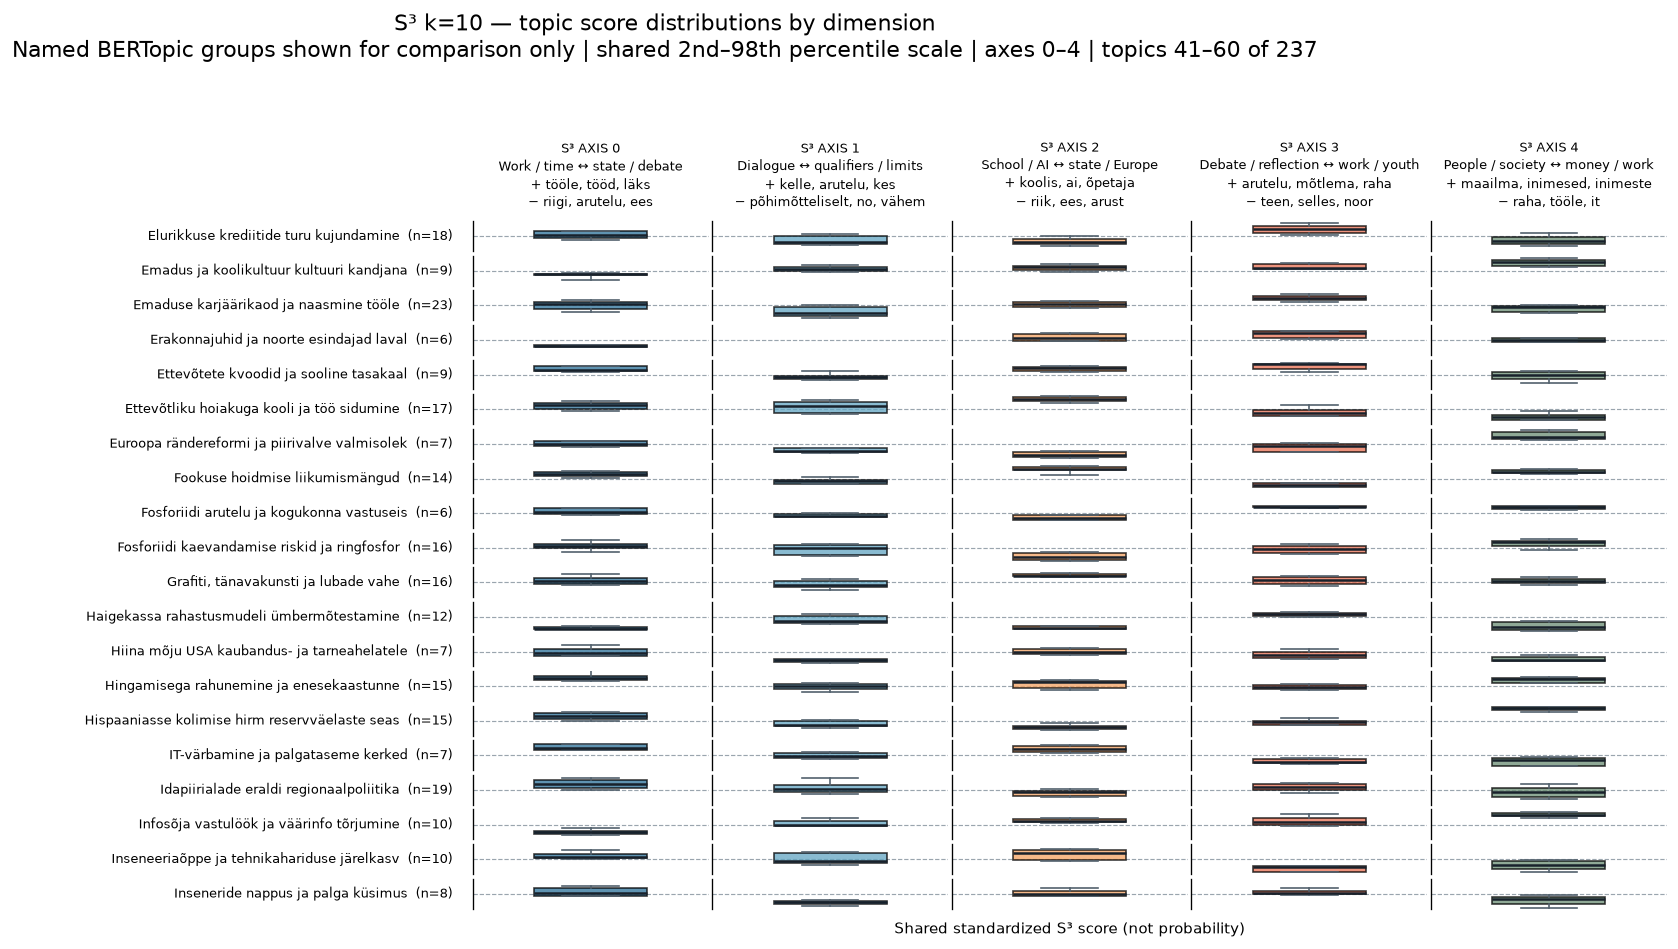

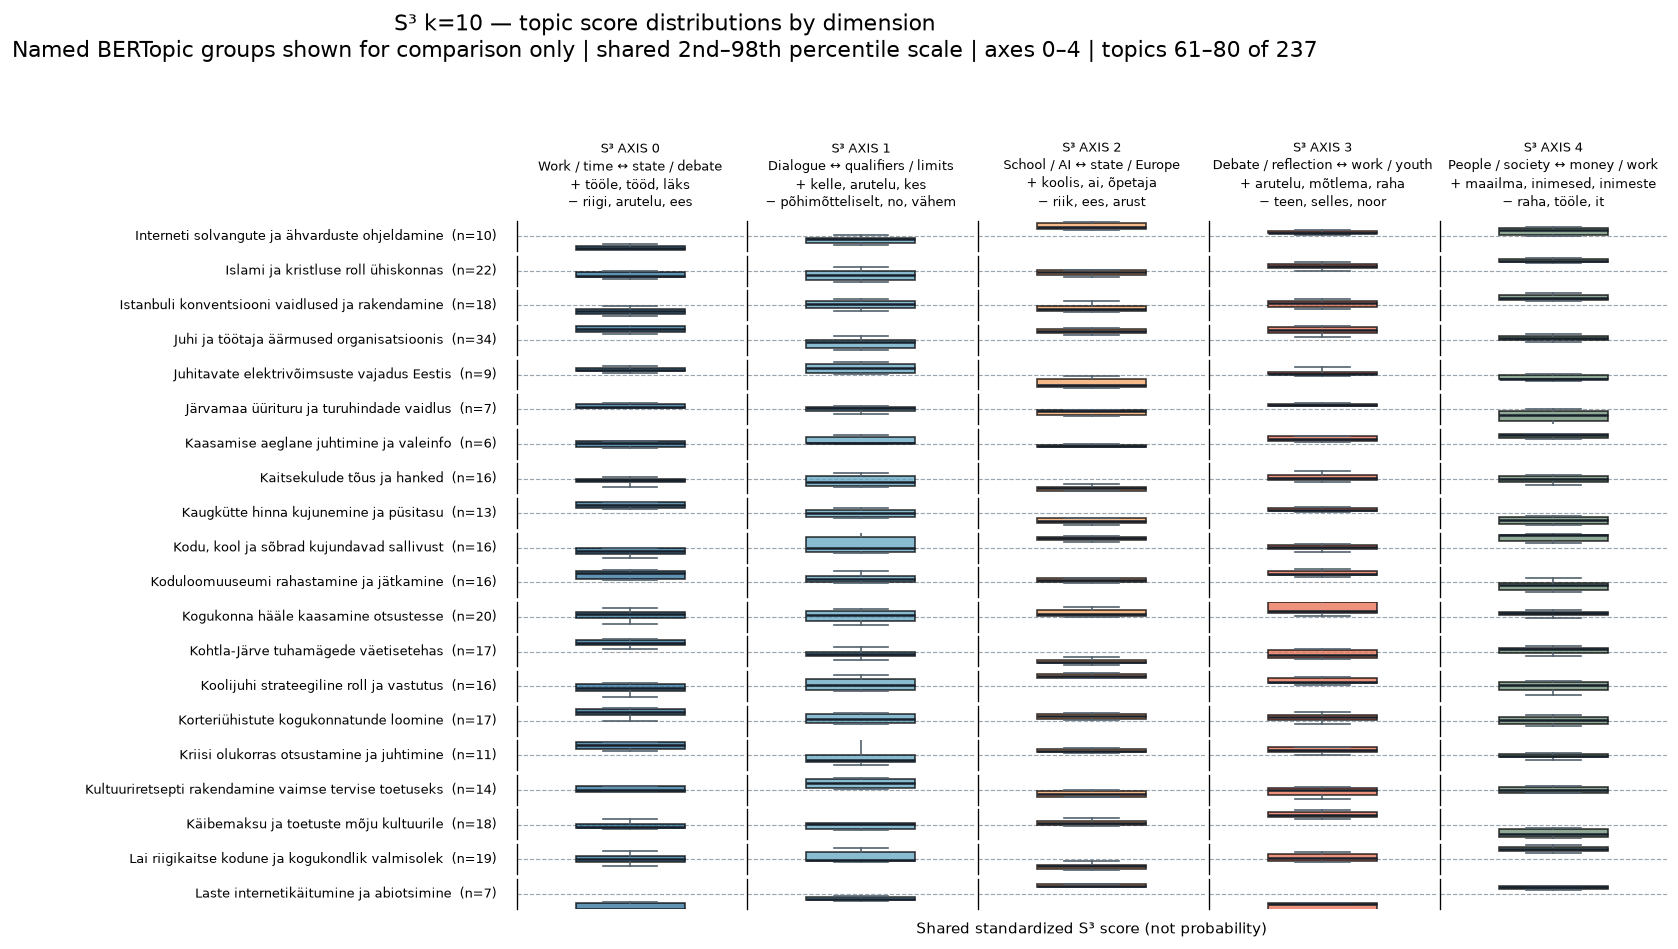

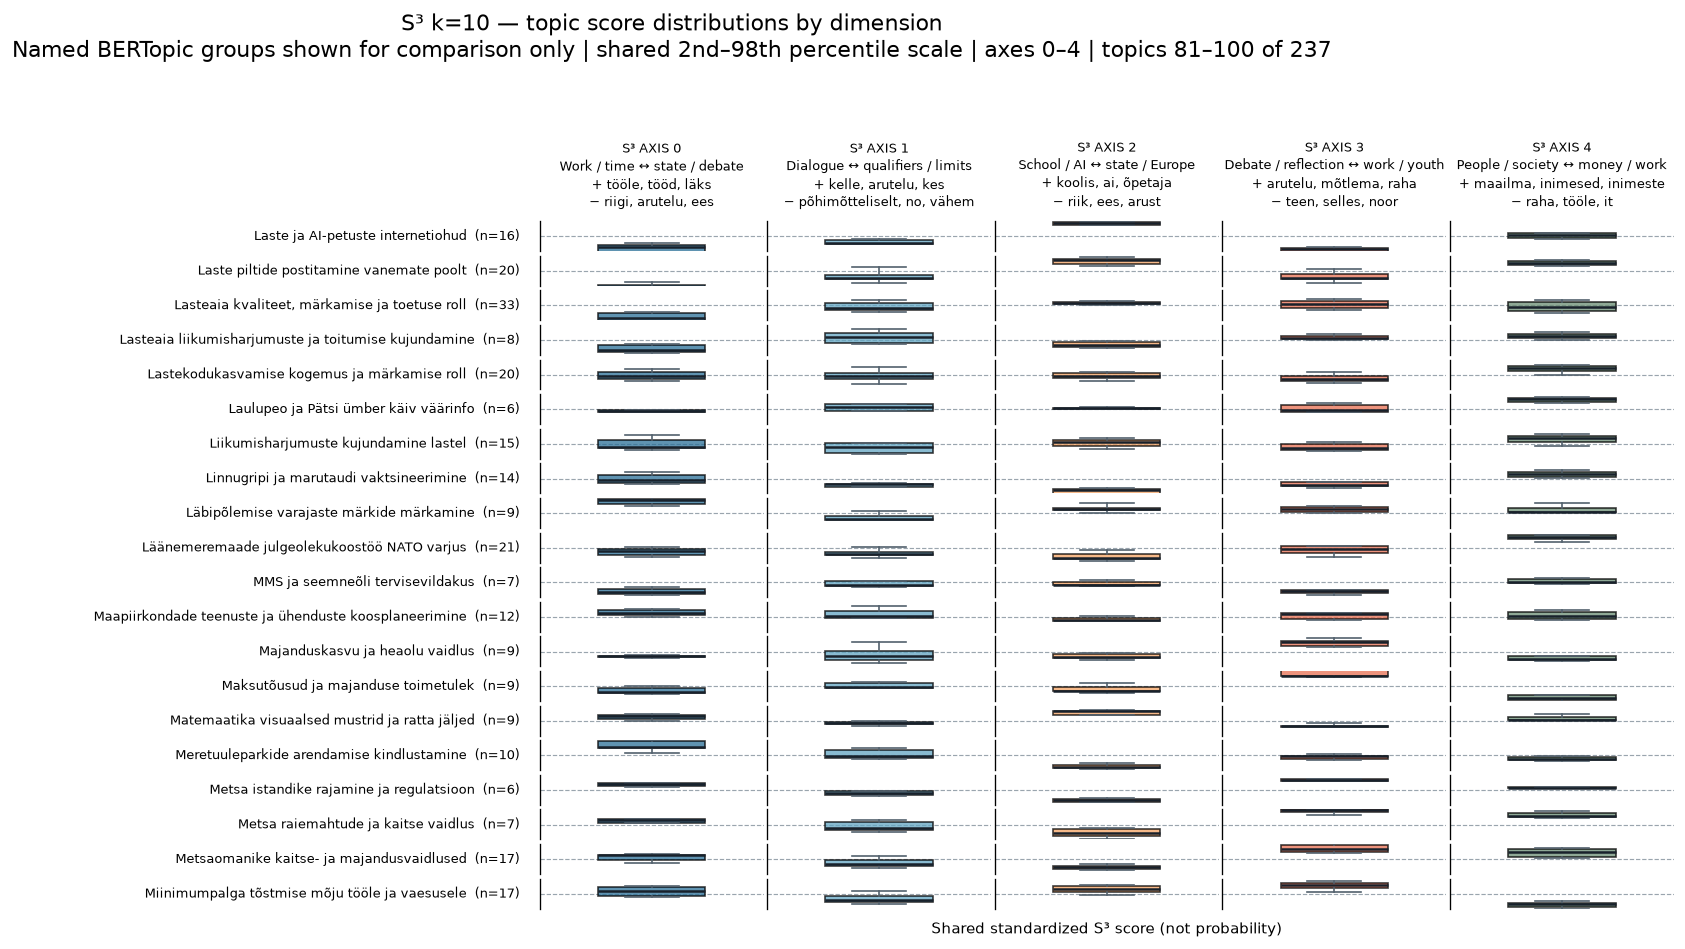

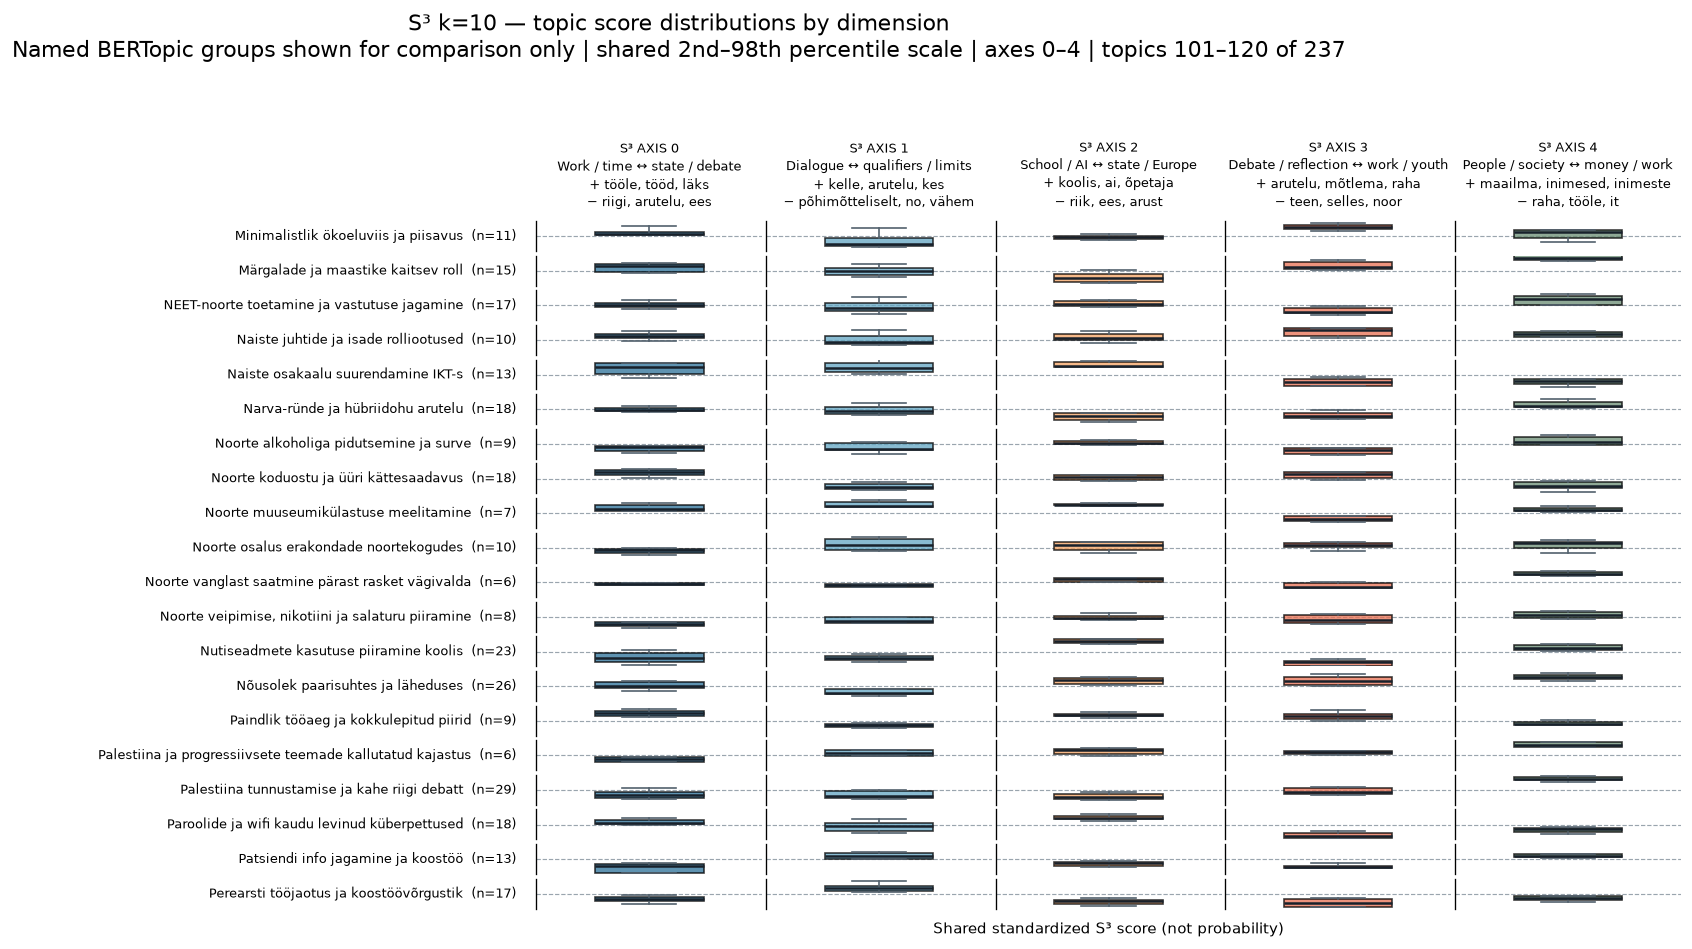

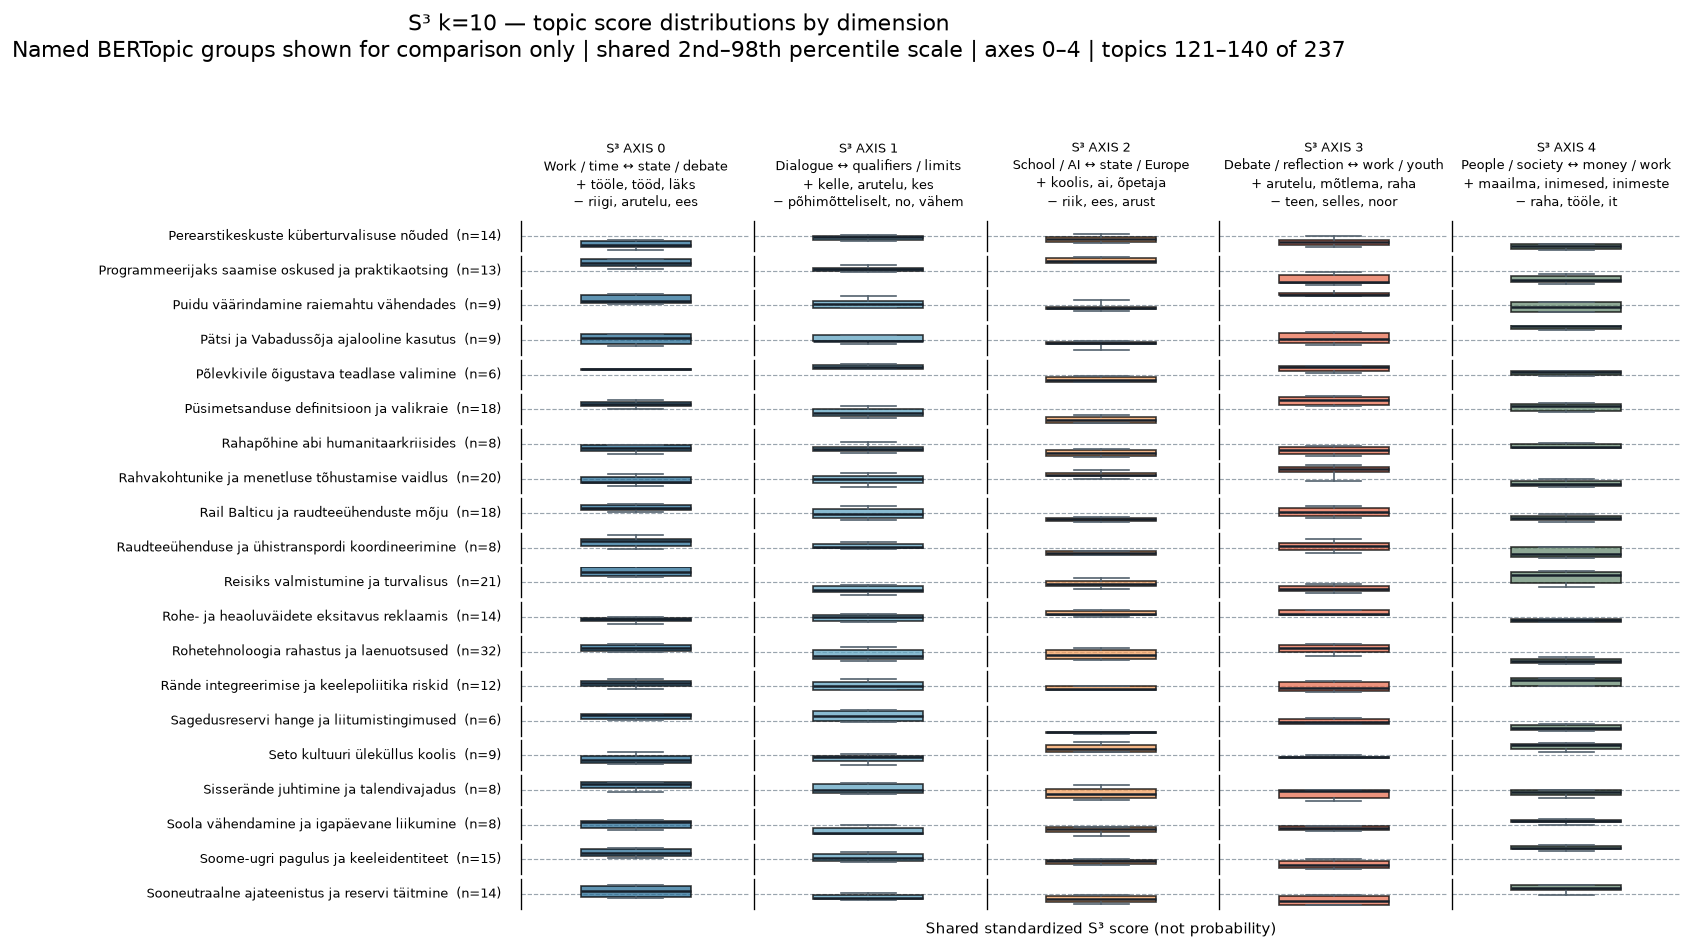

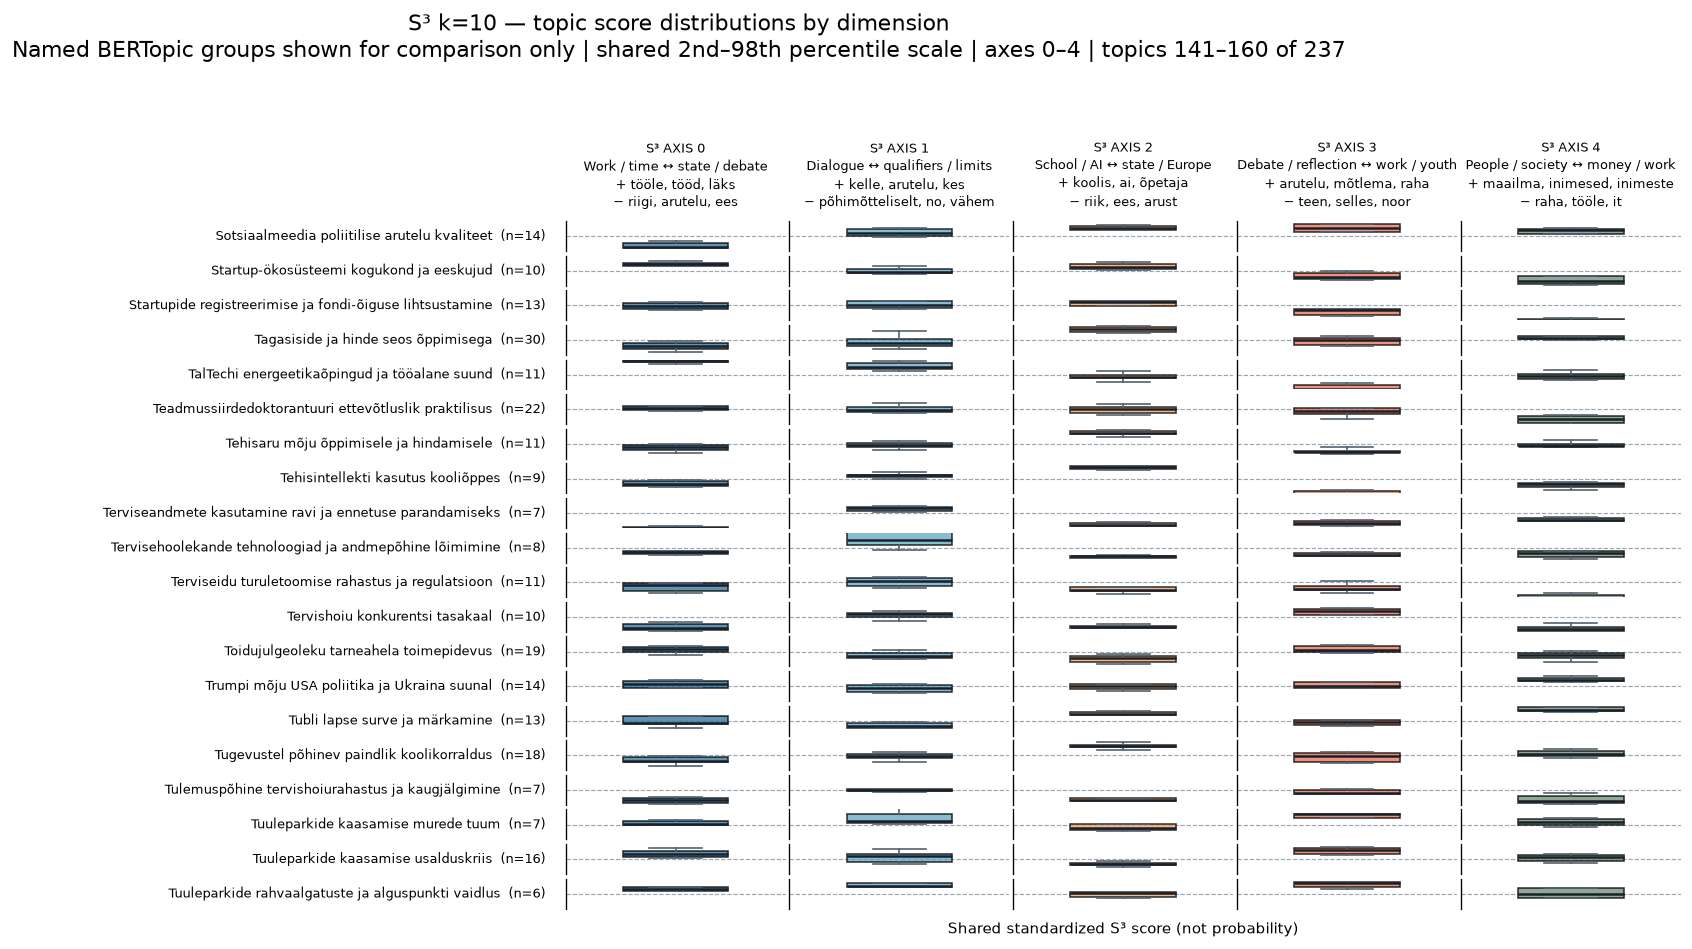

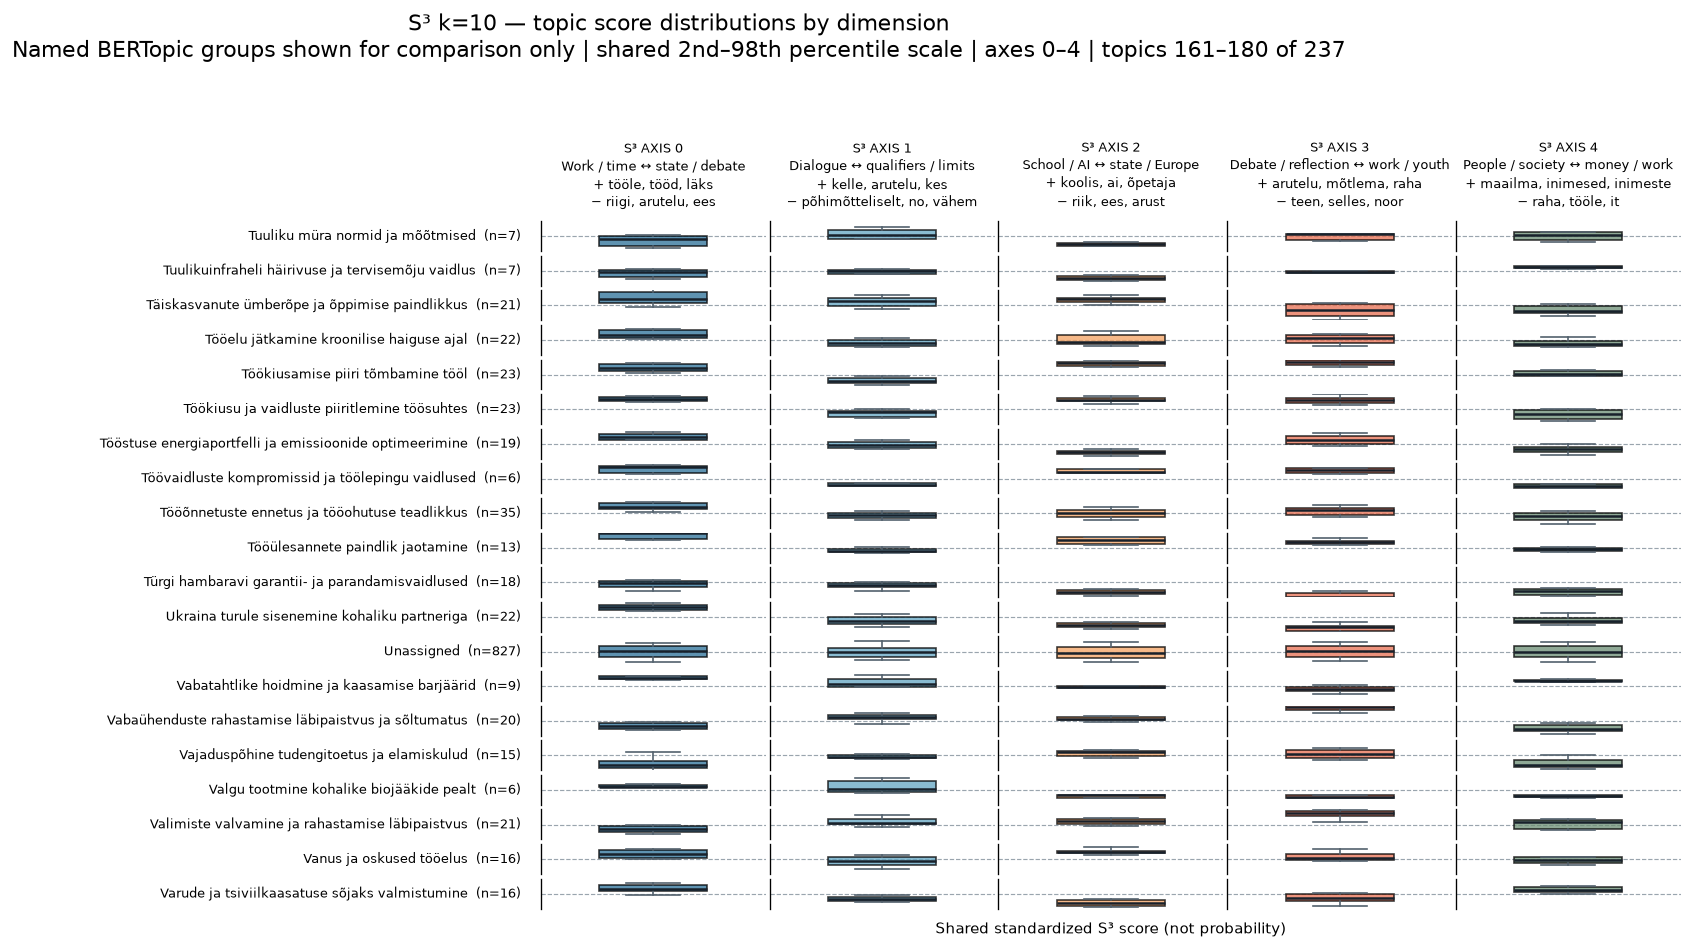

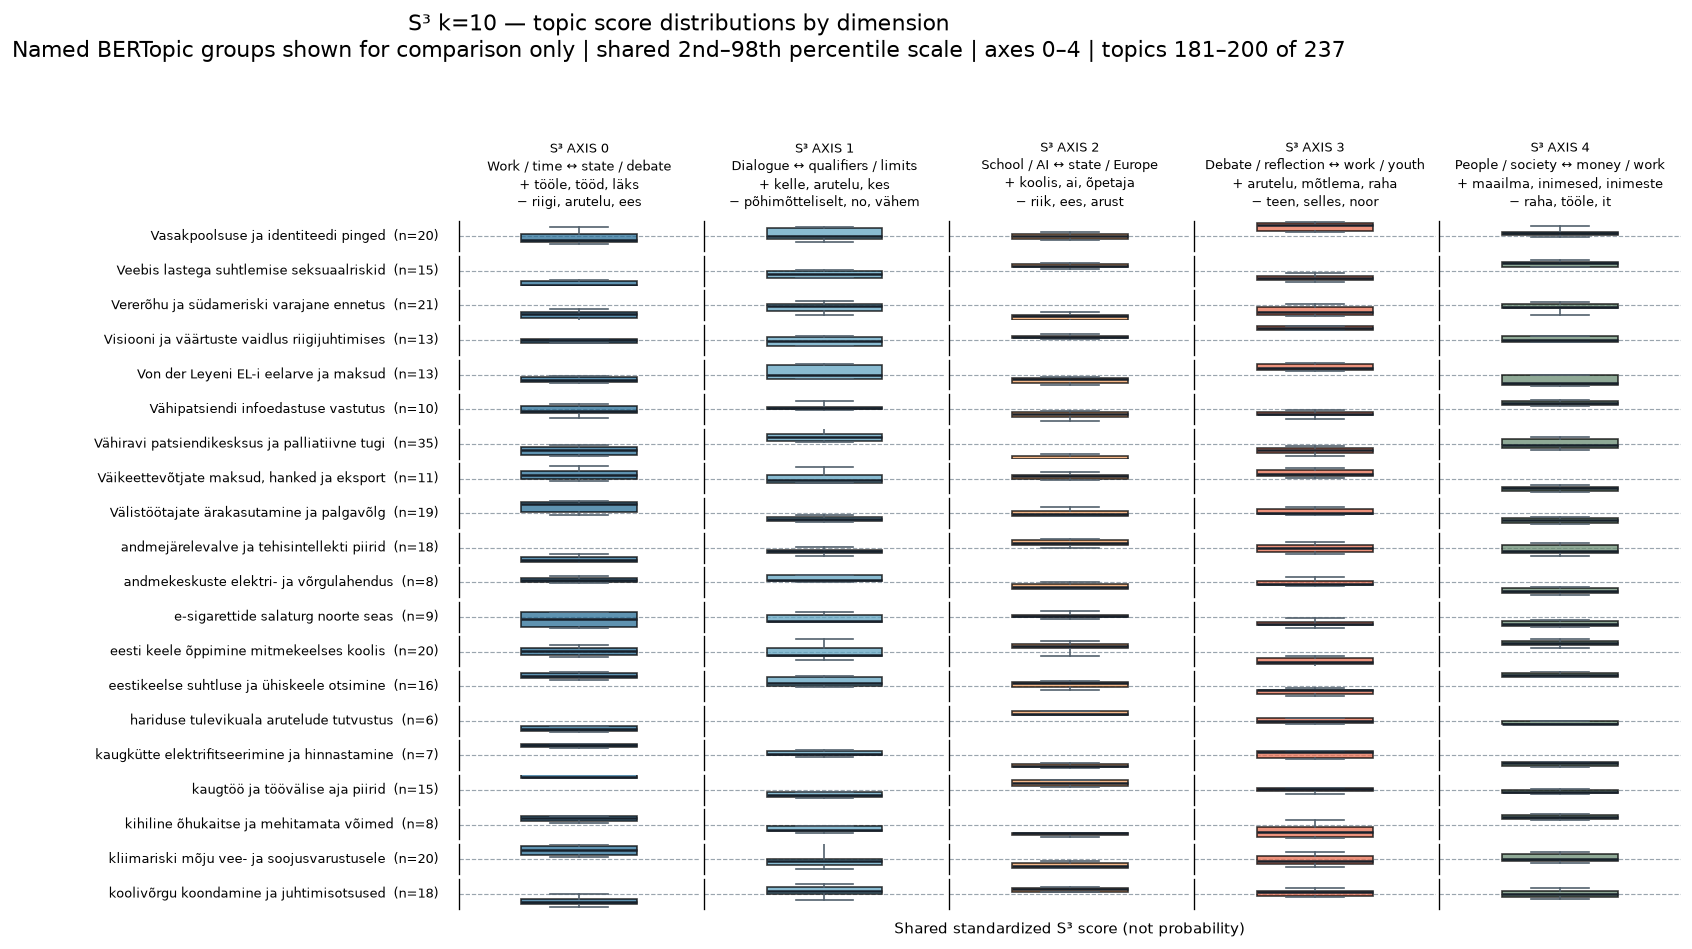

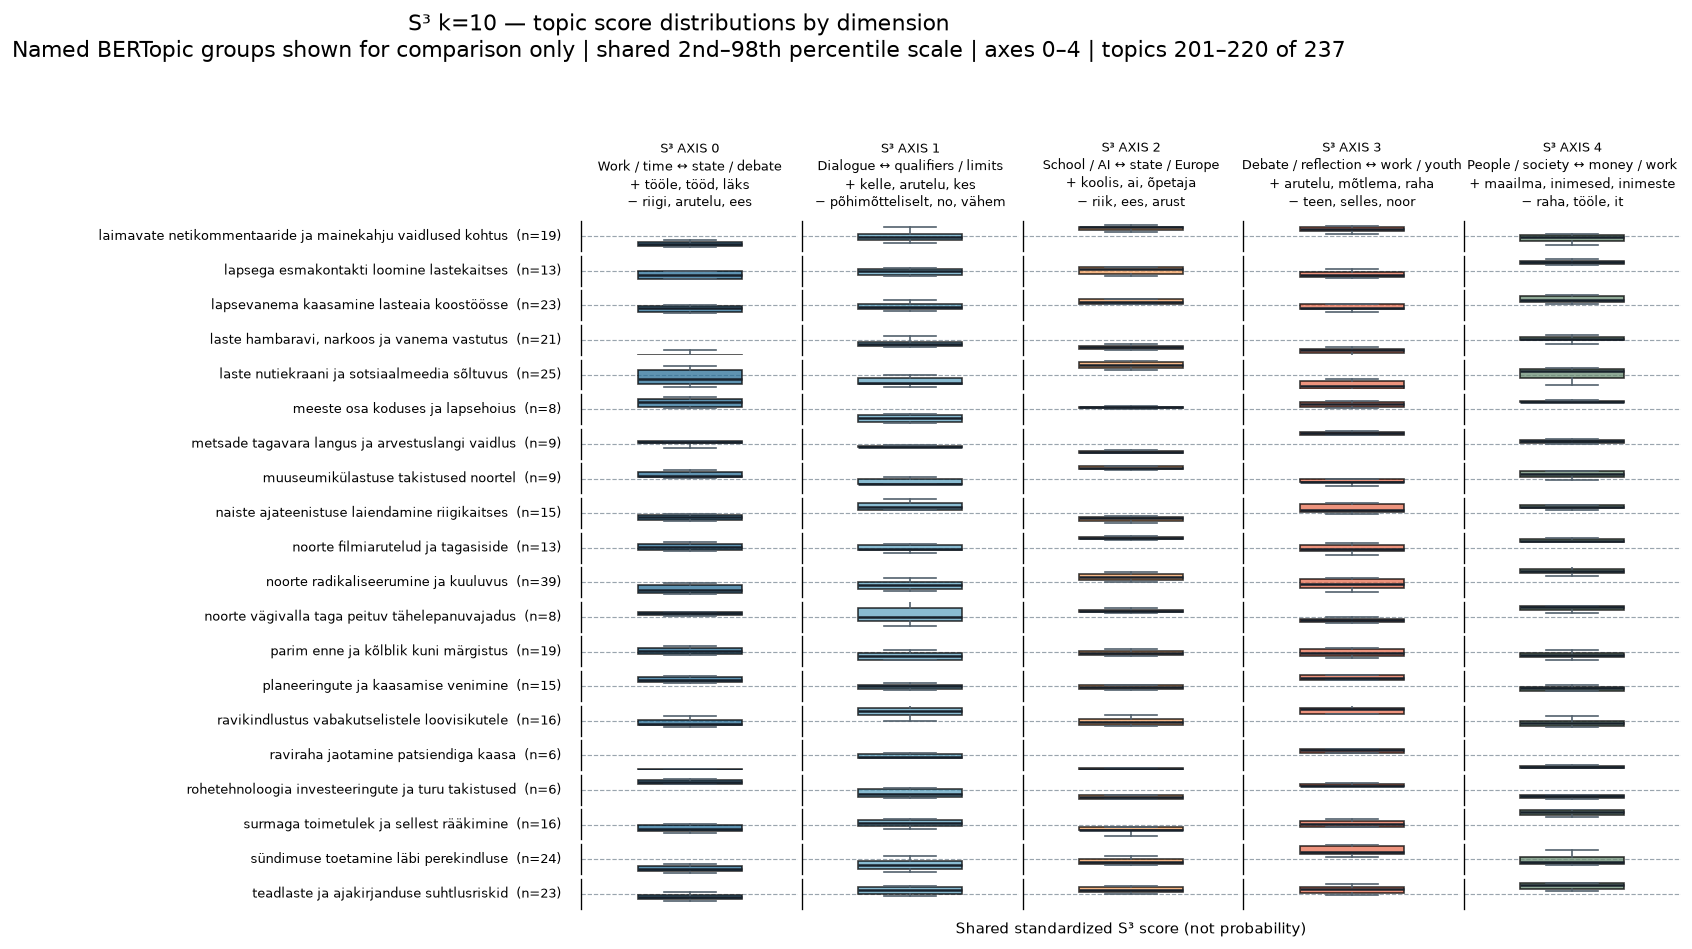

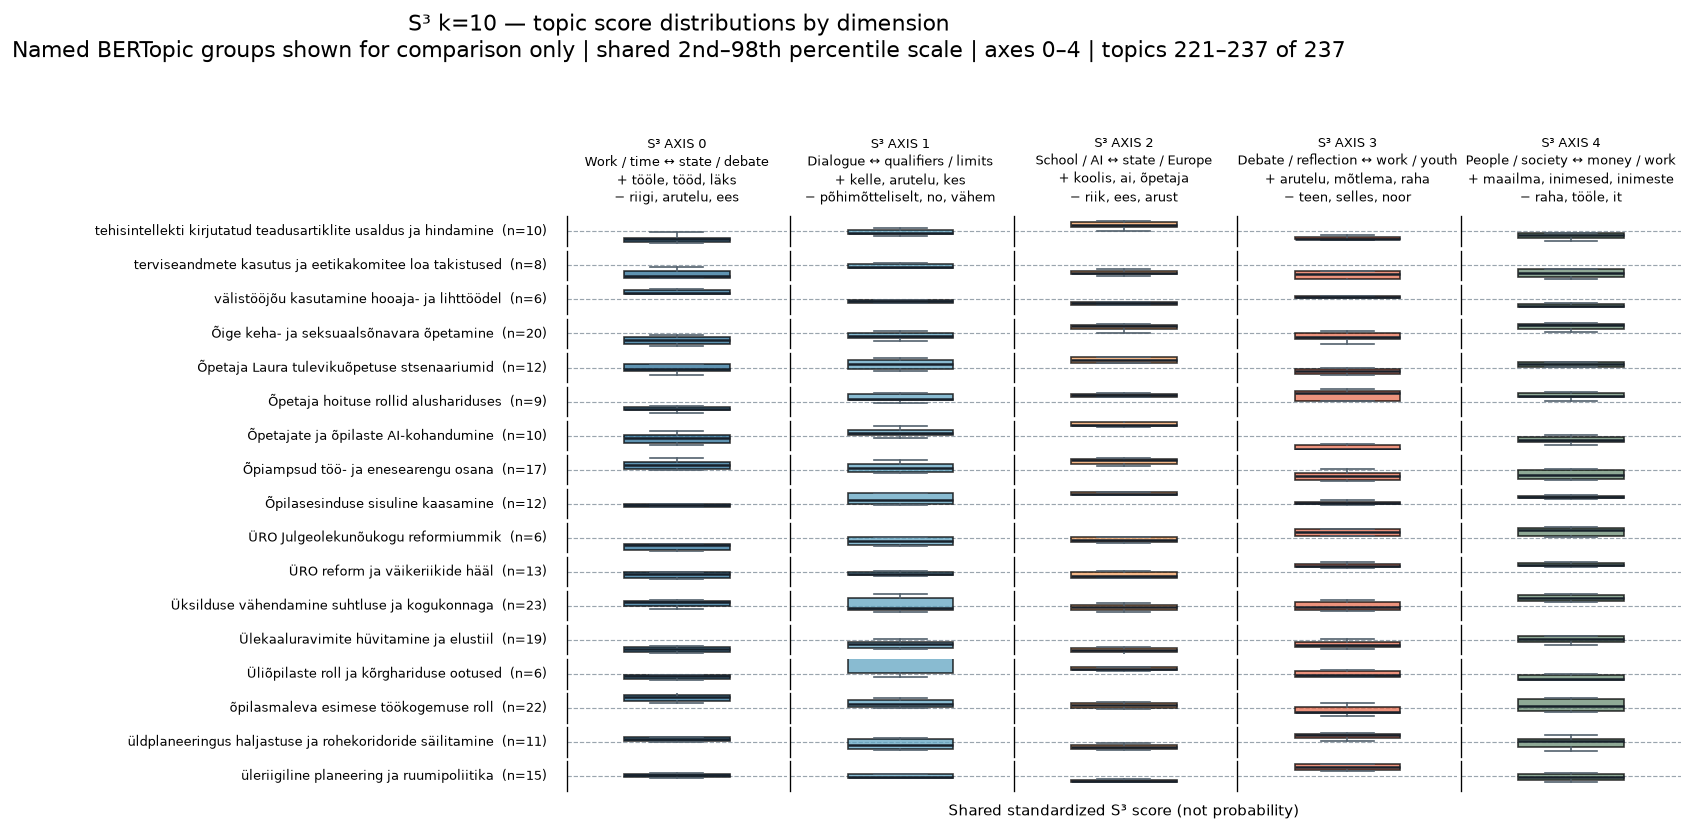

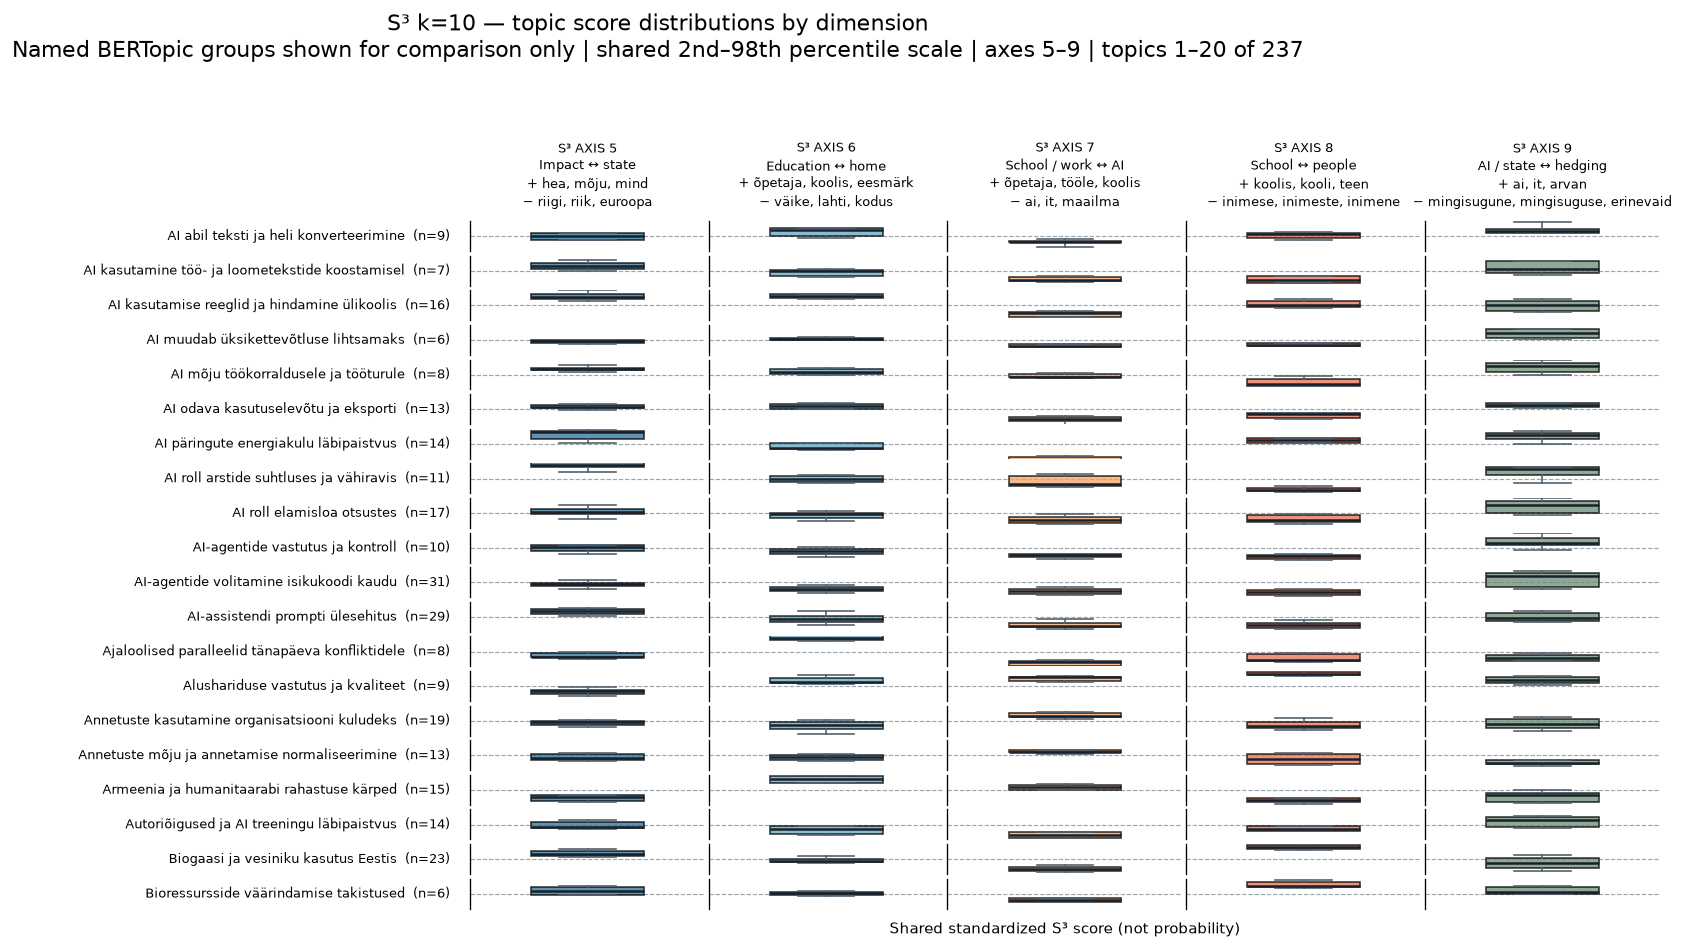

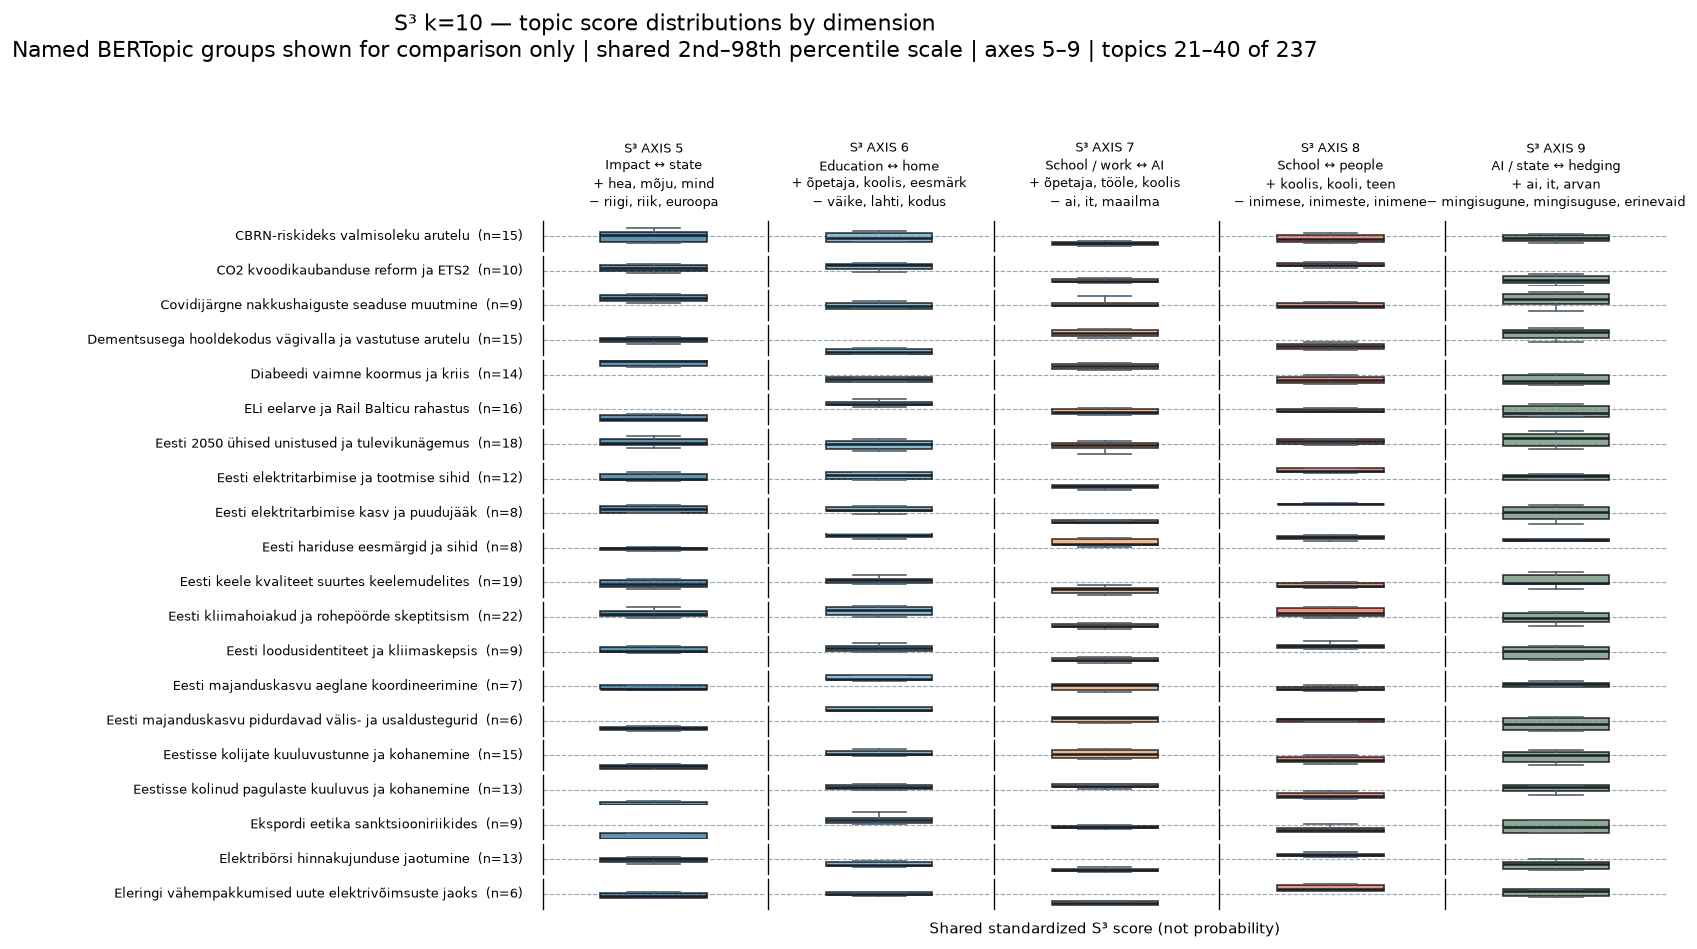

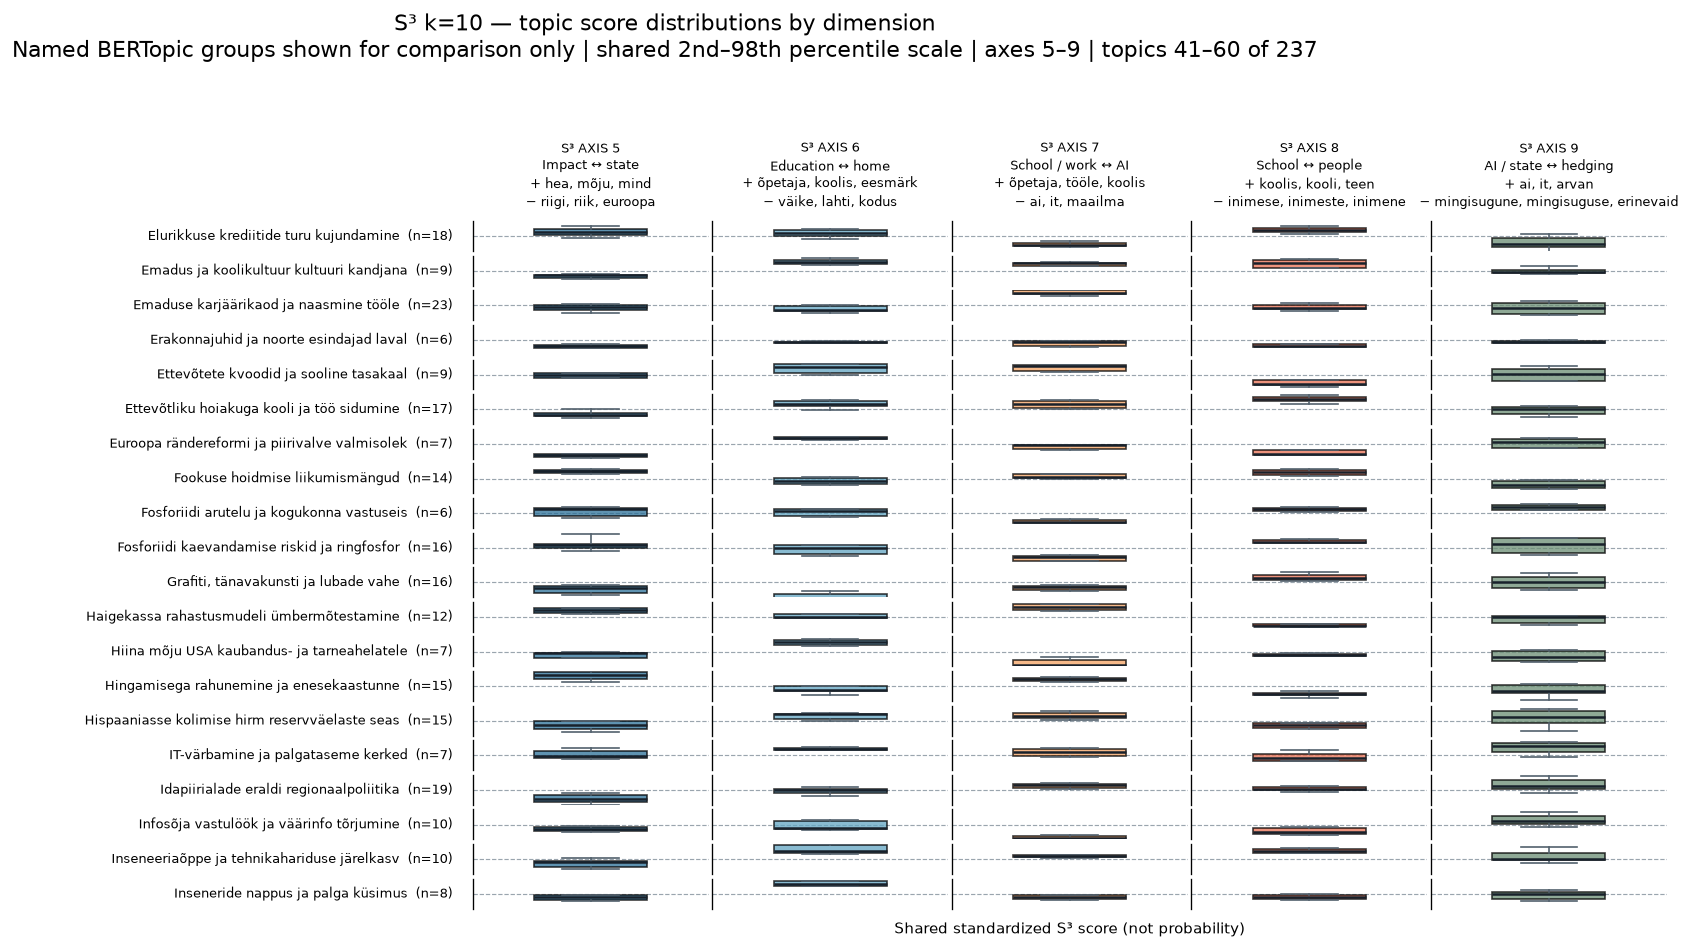

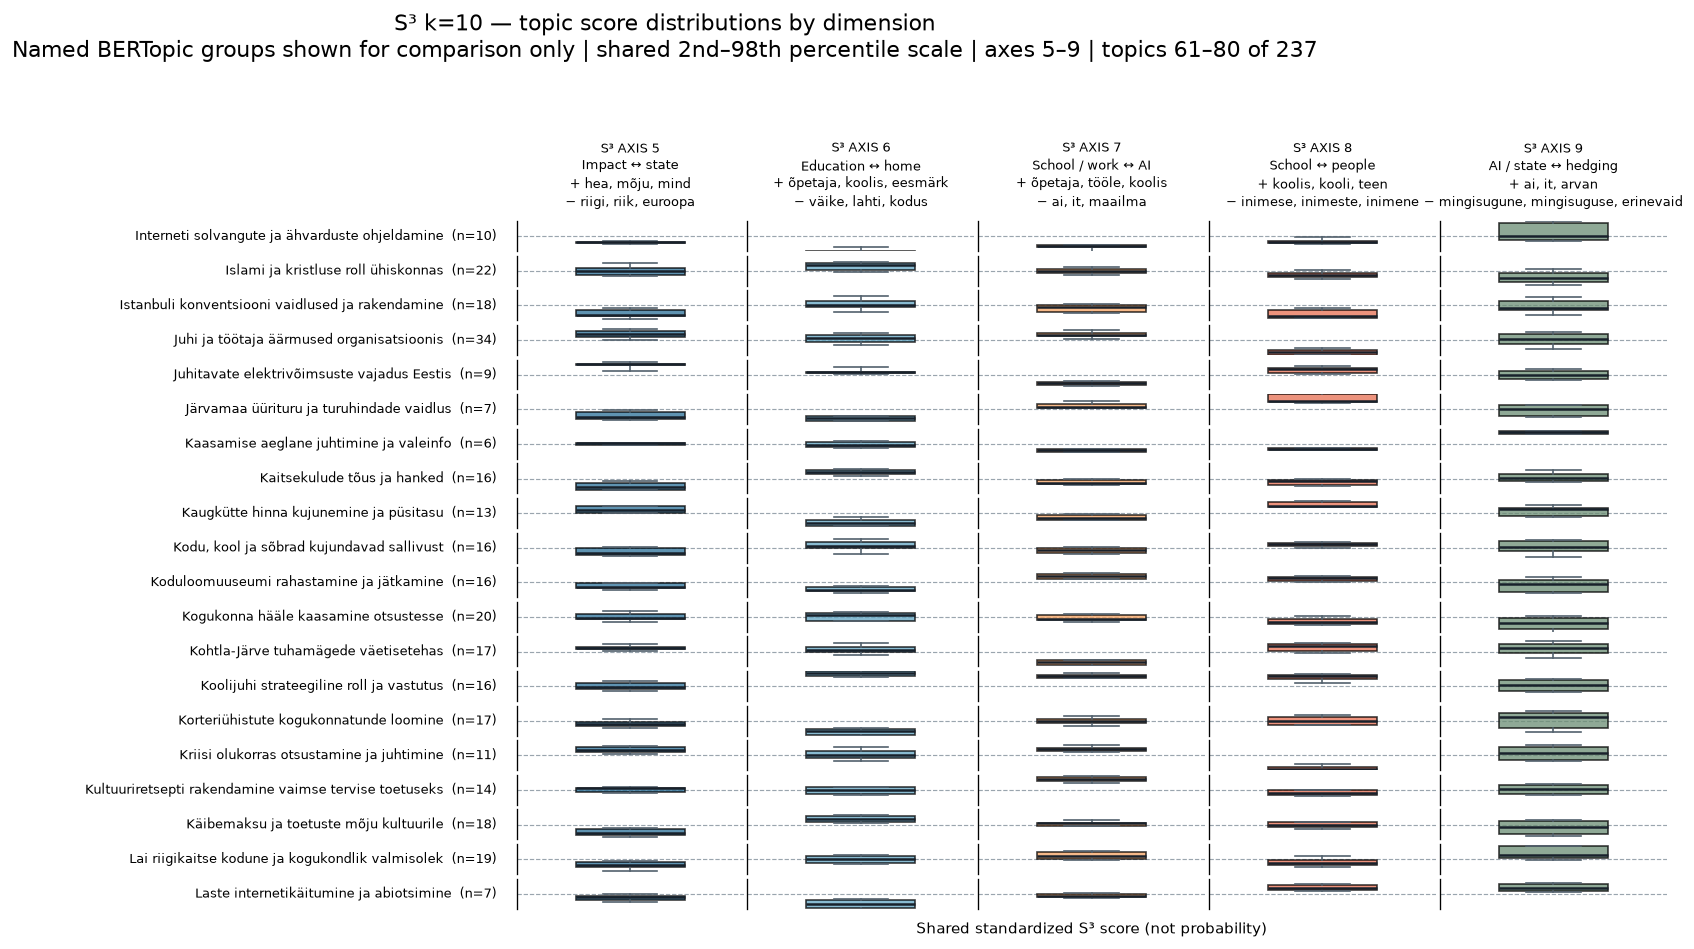

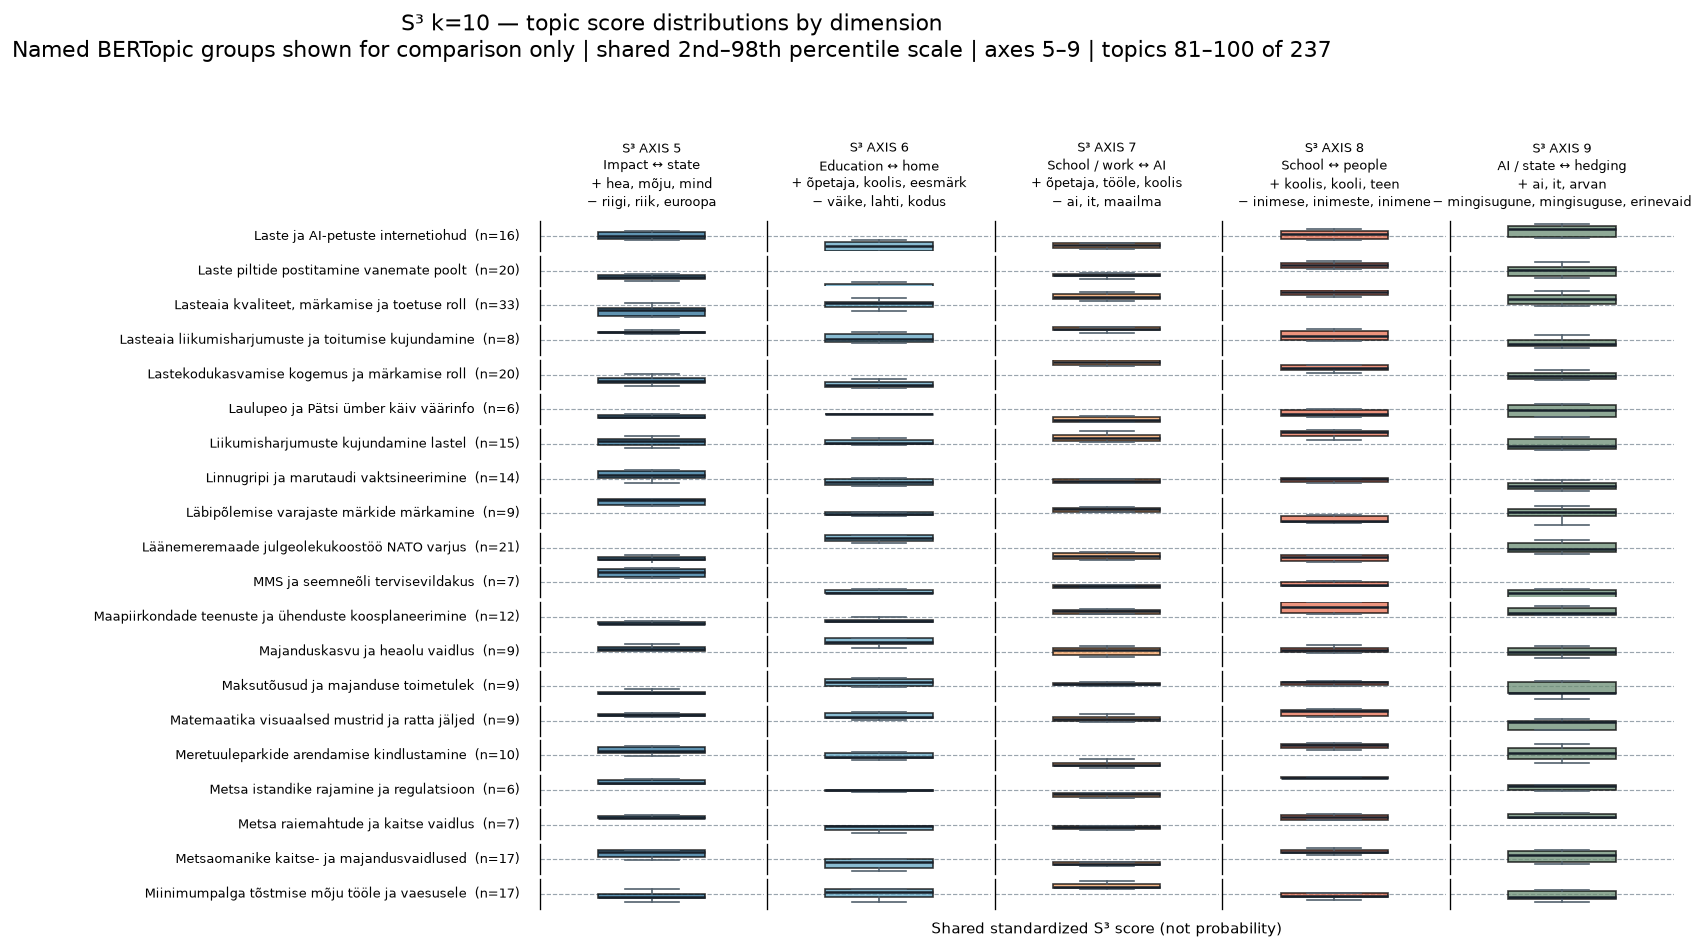

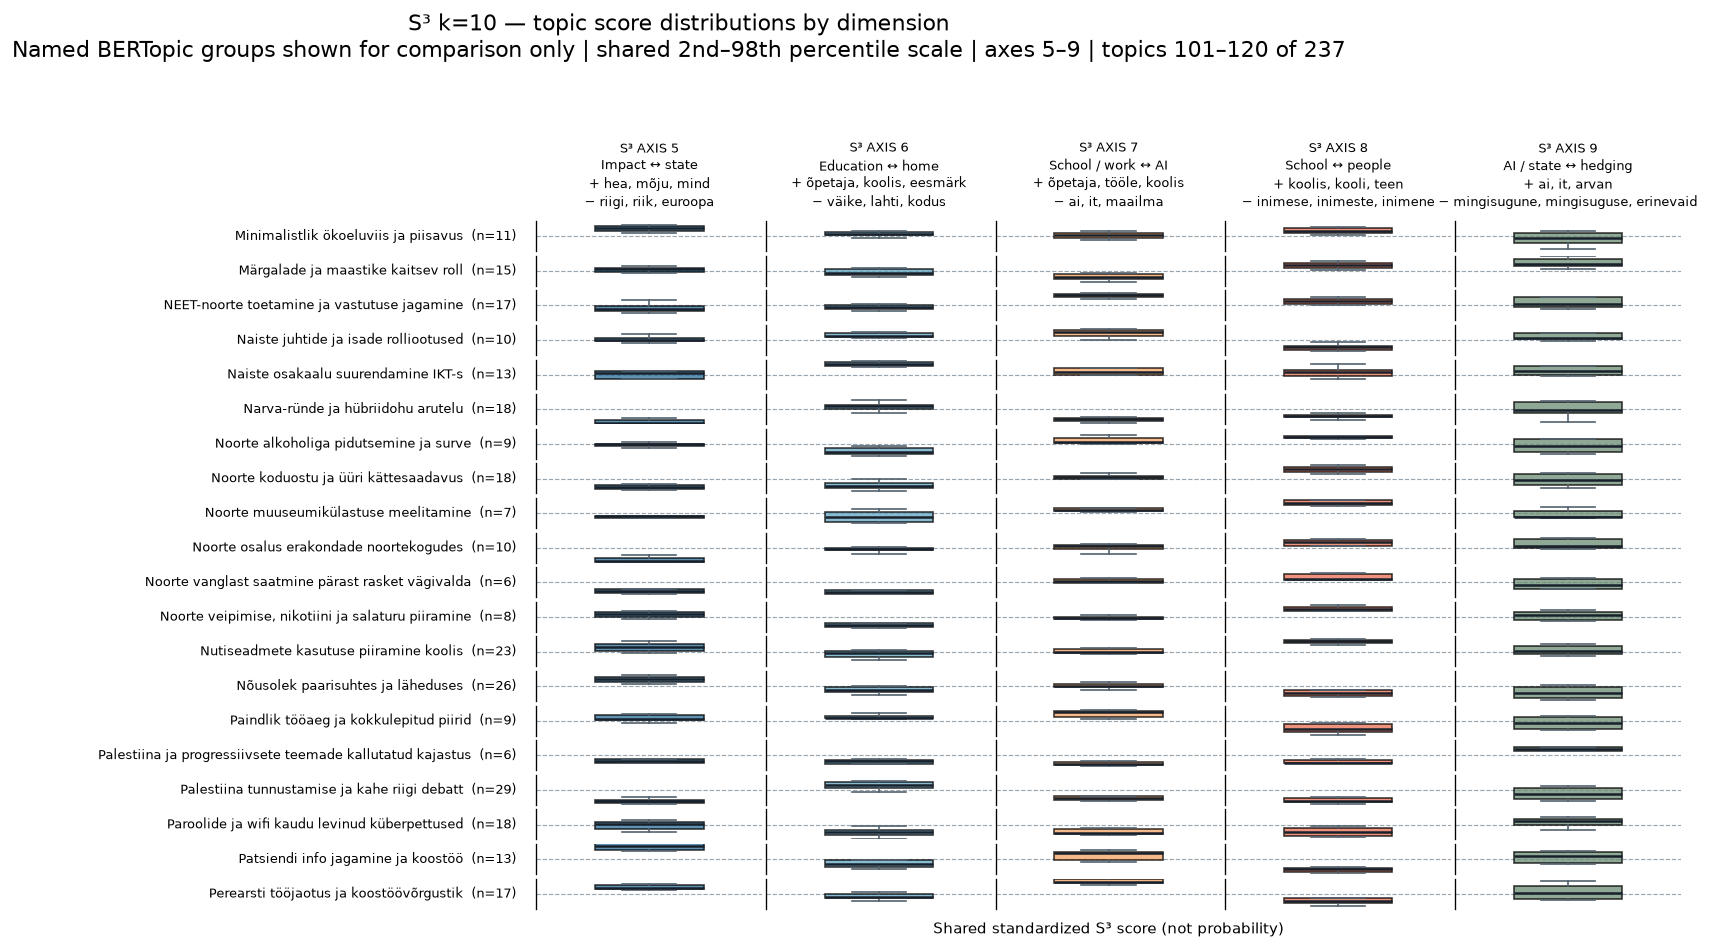

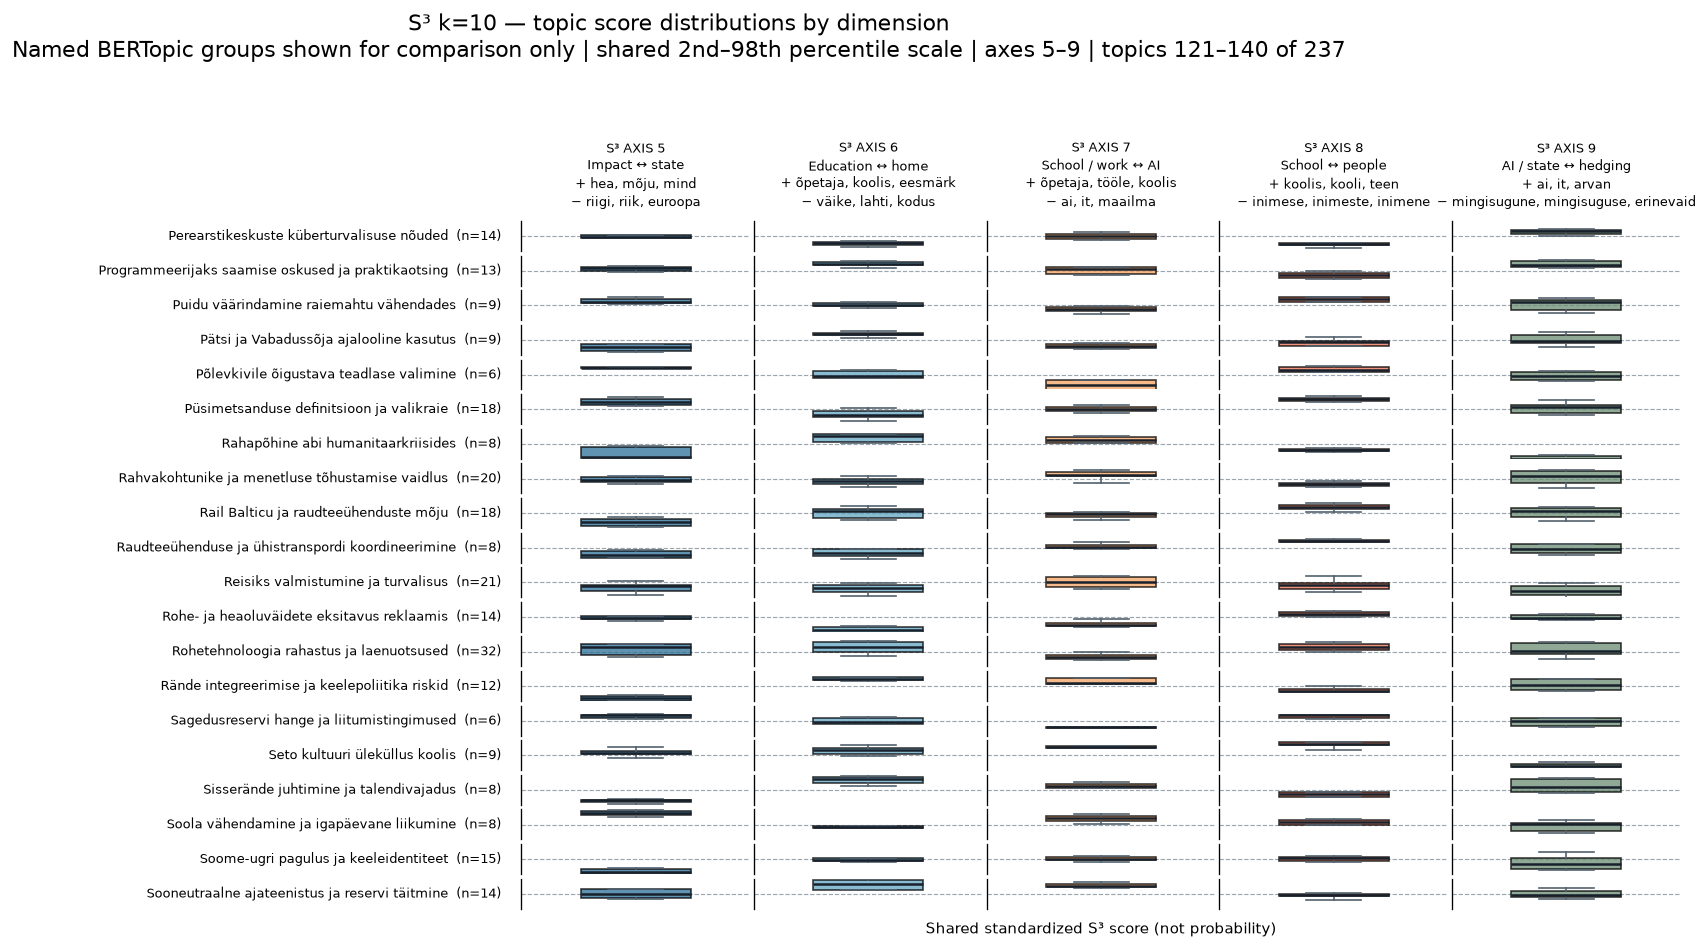

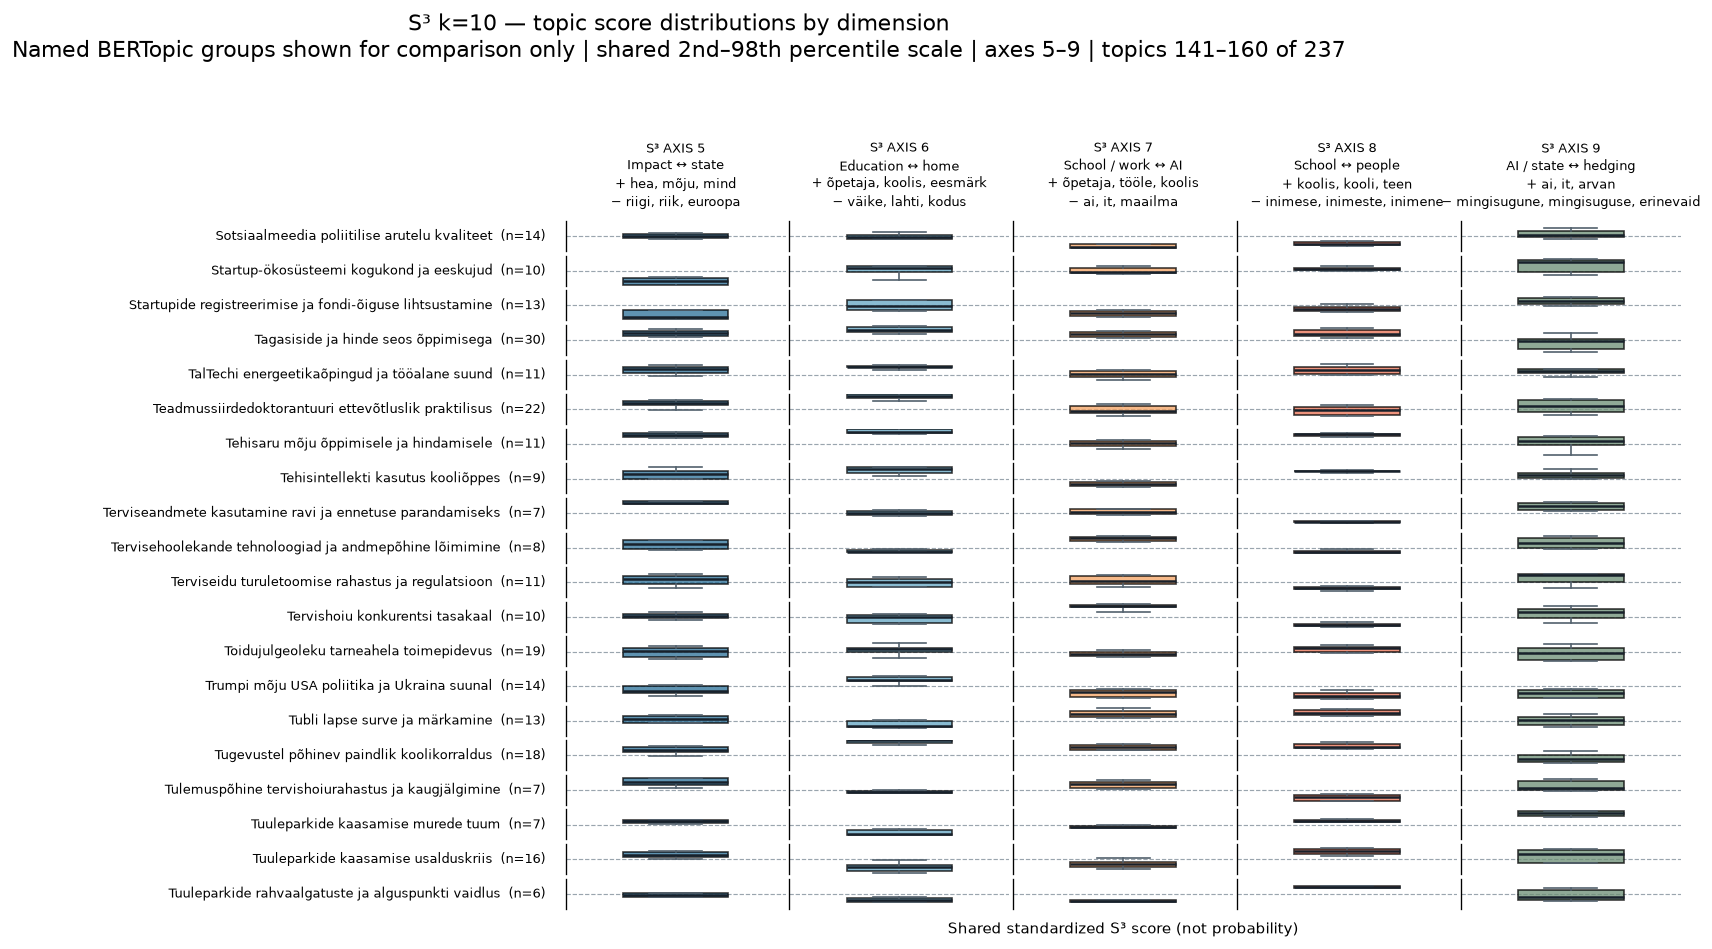

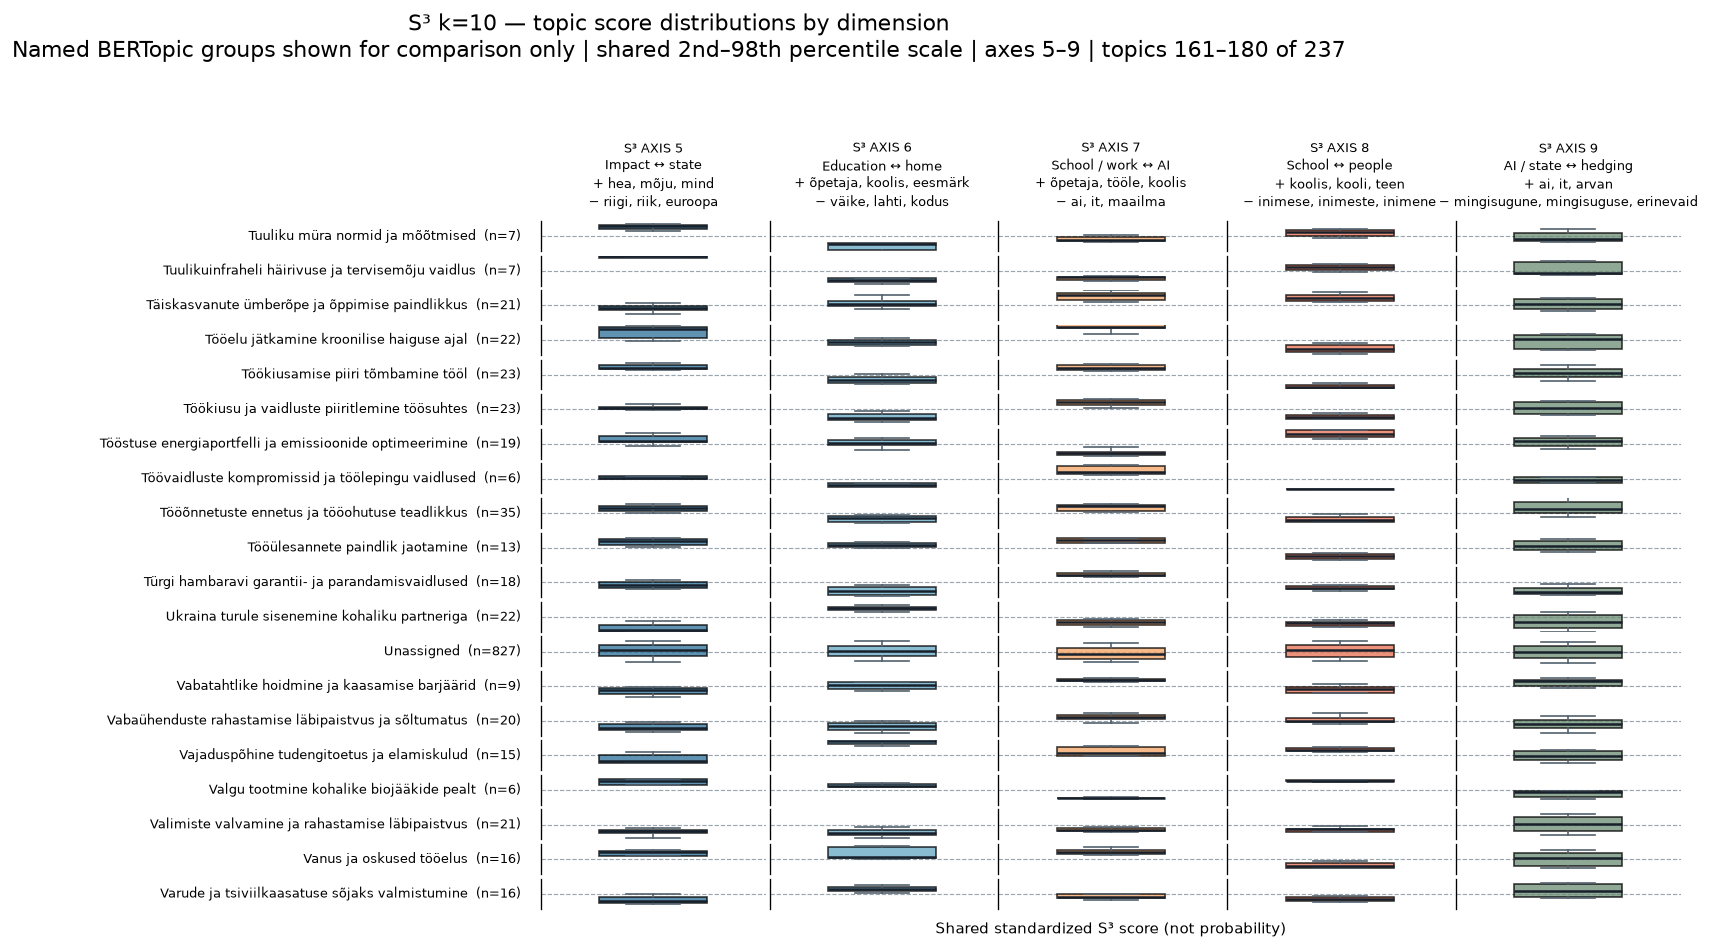

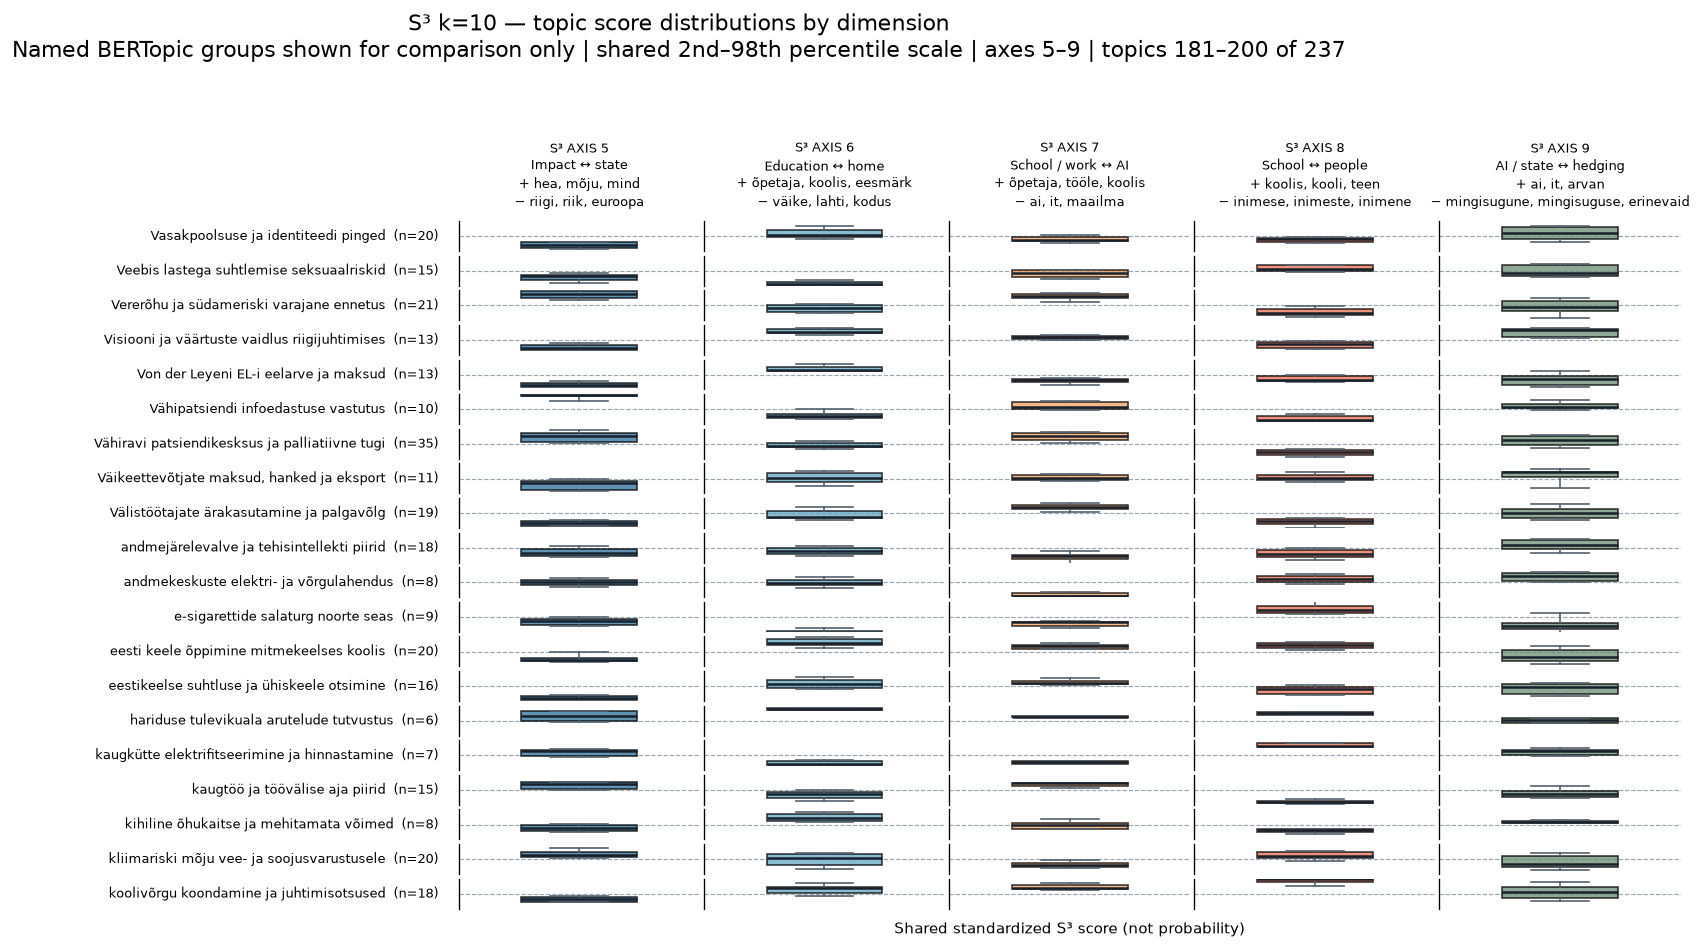

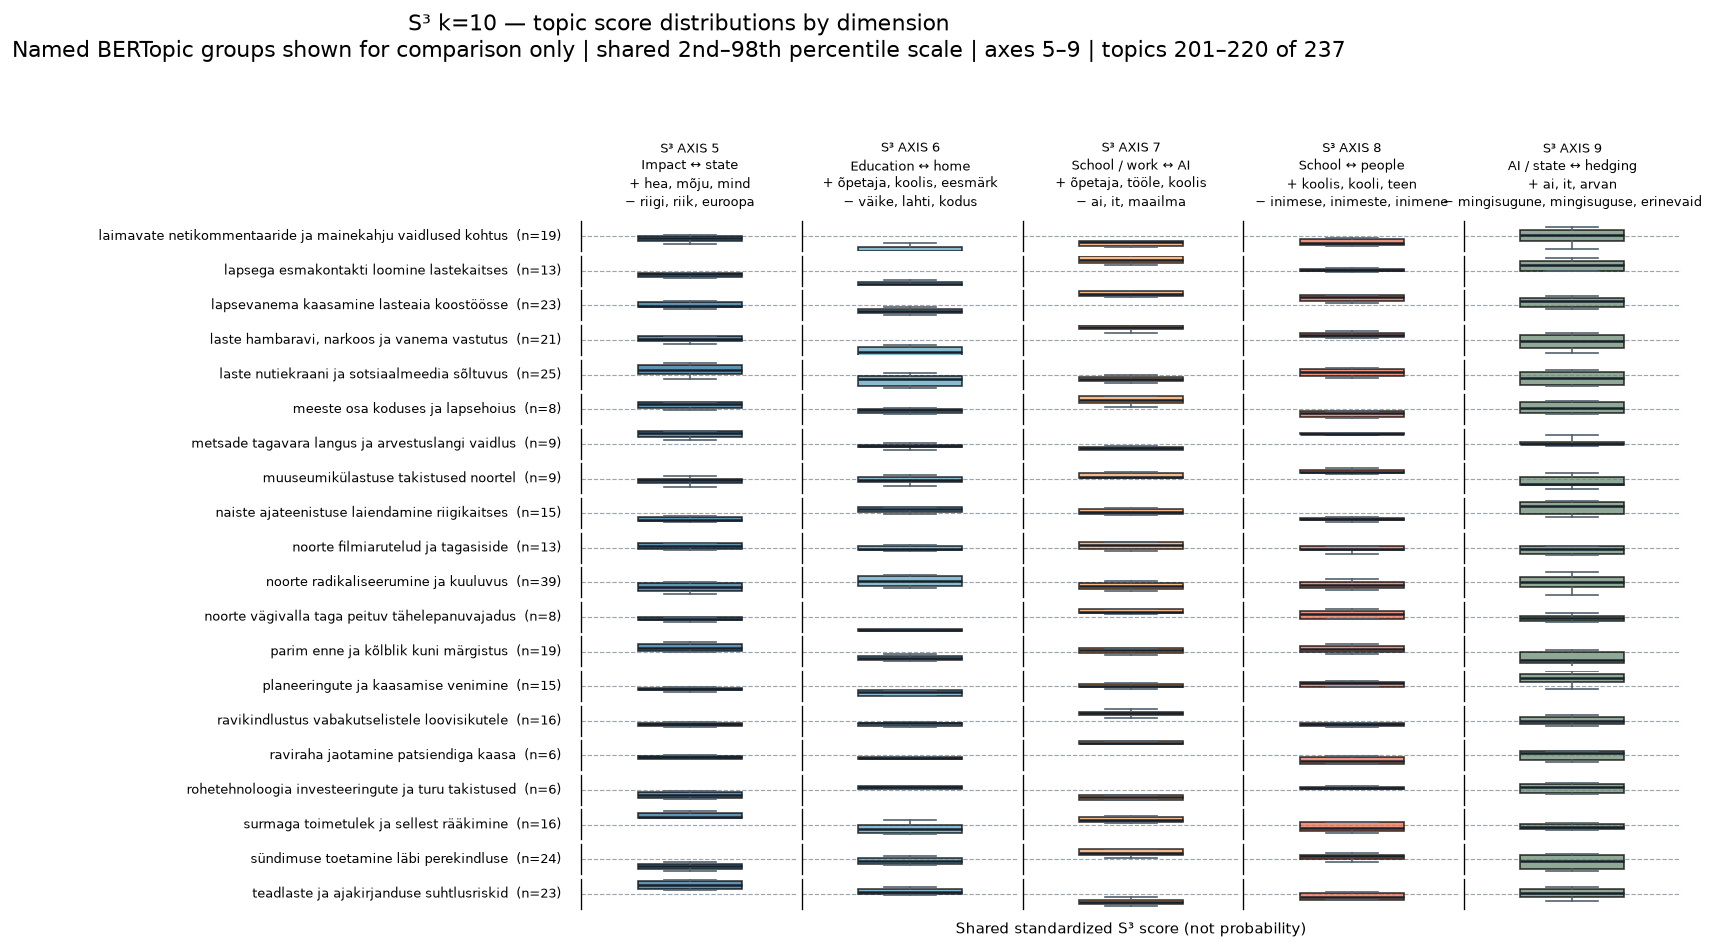

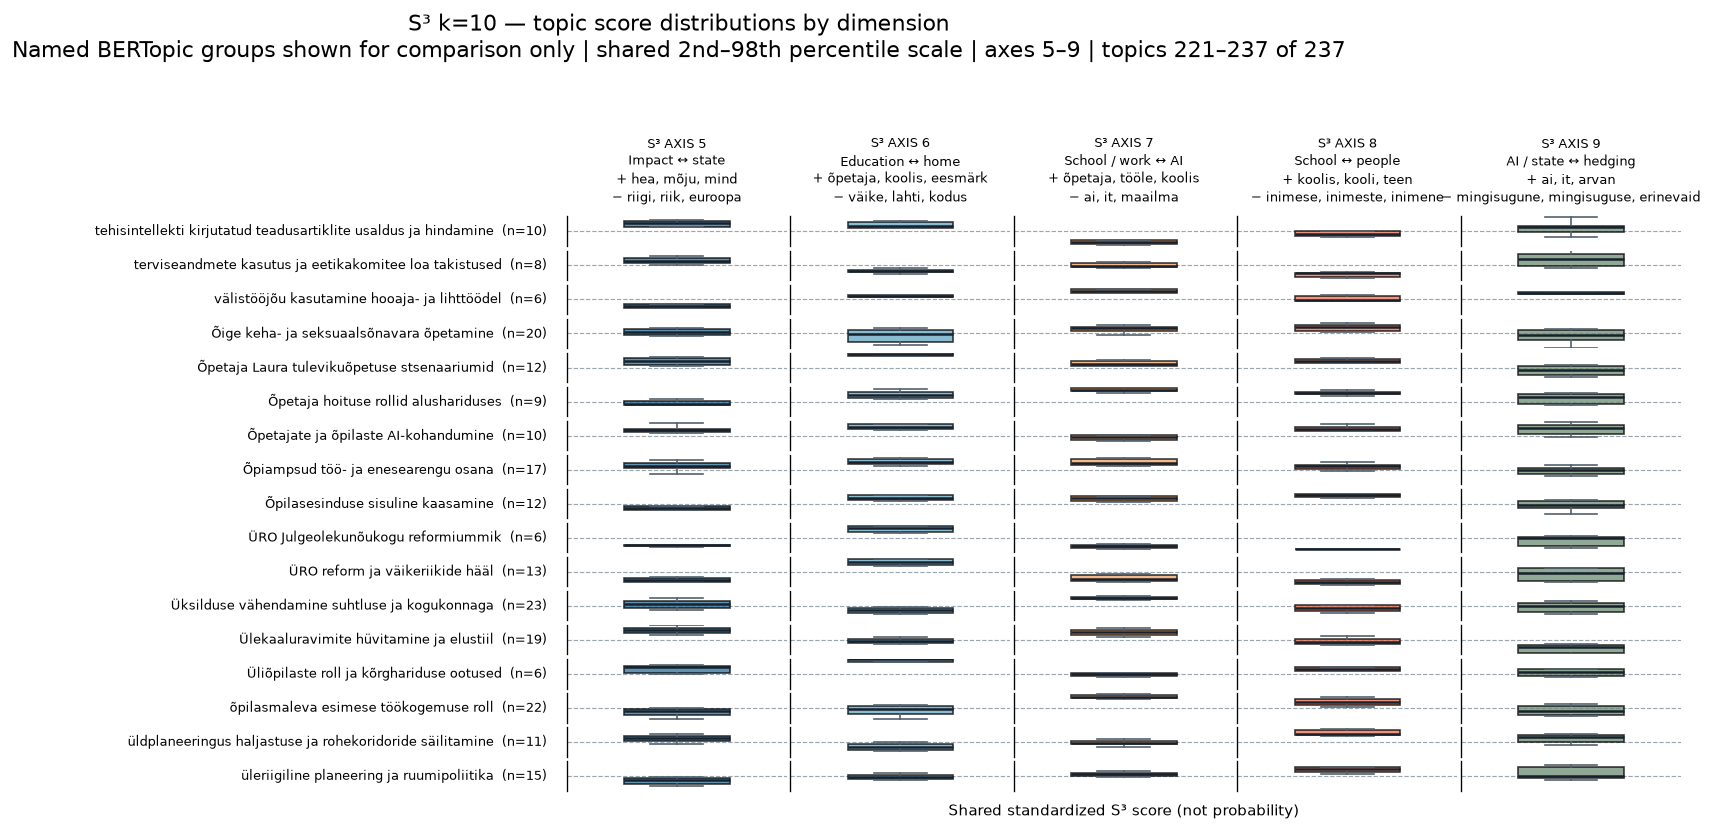

In [1]:
import sys
sys.path.insert(0, str(project_root))
import matplotlib.pyplot as plt
from IPython.display import Image
from scripts.s3_topic_axis import summarize_topic_axis_scores, build_topic_axis_review_tables, classify_topic_axis_percentiles

assert passages.topic_name.notna().all(), 'Every original BERTopic group must have a descriptive name.'
topic_names = passages.drop_duplicates('topic_id').set_index('topic_id').topic_name.to_dict()
topic_axis_summary = summarize_topic_axis_scores(passages, score_z)
topic_extremes, axis_keywords = build_topic_axis_review_tables(topic_axis_summary, topic_names, positive_terms, negative_terms)
axis_names = ['Work / time ↔ state / debate', 'Dialogue ↔ qualifiers / limits', 'School / AI ↔ state / Europe', 'Debate / reflection ↔ work / youth', 'People / society ↔ money / work', 'Impact ↔ state', 'Education ↔ home', 'School / work ↔ AI', 'School ↔ people', 'AI / state ↔ hedging']
axis_keywords['dimension_name'] = axis_names
topic_axis_percentiles = classify_topic_axis_percentiles(topic_axis_summary, lower_threshold=0.30, upper_threshold=0.70)
topic_axis_percentiles['topic_name'] = topic_axis_percentiles.topic_id.map(topic_names)
topic_axis_percentiles['dimension_name'] = topic_axis_percentiles.axis_id.map(dict(enumerate(axis_names)))
high_dimensions = topic_axis_percentiles.query("status == 'high'").groupby('topic_id').dimension_name.agg(', '.join).rename('high_dimensions')
low_dimensions = topic_axis_percentiles.query("status == 'low'").groupby('topic_id').dimension_name.agg(', '.join).rename('low_dimensions')
topic_extremes = topic_extremes.merge(high_dimensions, on='topic_id', how='left').merge(low_dimensions, on='topic_id', how='left')
topic_extremes[['high_dimensions', 'low_dimensions']] = topic_extremes[['high_dimensions', 'low_dimensions']].fillna('—')
axis_output_dir = results / 'jev-semantic-all' / 's3-topic-axis-distributions'
axis_output_dir.mkdir(parents=True, exist_ok=True)
run_tag = f'k{N_COMPONENTS}-seed{RANDOM_STATE}'
passage_score_path = axis_output_dir / f'passage-scores-{run_tag}.parquet'
topic_summary_path = axis_output_dir / f'topic-axis-summary-{run_tag}.parquet'
topic_extremes_path = axis_output_dir / f'topic-axis-extremes-{run_tag}.csv'
axis_keywords_path = axis_output_dir / f'axis-keywords-{run_tag}.csv'
scored_passages.to_parquet(passage_score_path, index=False)
topic_axis_summary.to_parquet(topic_summary_path, index=False)
for prefix, axis_col in [('highest', 'highest_axis_id'), ('lowest', 'lowest_axis_id')]:
    topic_extremes[f'{prefix}_dimension'] = topic_extremes[axis_col].map(dict(enumerate(axis_names)))
topic_extremes.to_csv(topic_extremes_path, index=False)
axis_keywords.to_csv(axis_keywords_path, index=False)
percentiles_path = axis_output_dir / f'topic-axis-percentiles-{run_tag}.csv'
topic_axis_percentiles.to_csv(percentiles_path, index=False)
print('High = above the 70th percentile; Low = below the 30th percentile among topic groups, ranked separately for each axis. Exact boundaries and the middle 40% are Typical. These are relative comparisons, not probabilities.')
display(axis_keywords[['axis_id', 'dimension_name', 'positive_end_keywords', 'negative_end_keywords']])
visible = ['topic_name', 'passage_count', 'high_dimensions', 'low_dimensions', 'highest_dimension', 'highest_mean_z', 'highest_axis_positive_keywords', 'lowest_dimension', 'lowest_mean_z', 'lowest_axis_negative_keywords'] + [f'axis_{i}_mean_z' for i in range(N_COMPONENTS)]
display(topic_extremes[visible].sort_values('topic_name').reset_index(drop=True))

topics_per_page = 20
axes_per_panel = 5
topic_order = topic_extremes.sort_values('topic_name').topic_id.tolist()
plot_dir = axis_output_dir / 'static-plots-k10-seed42'
plot_dir.mkdir(parents=True, exist_ok=True)
plot_low, plot_high = np.nanpercentile(score_z.to_numpy(), [2, 98])
axis_colors = ['#2A6F97', '#61A5C2', '#F4A261', '#E76F51', '#6A8D73']
for axis_start in range(0, N_COMPONENTS, axes_per_panel):
    axis_ids = list(range(axis_start, min(axis_start + axes_per_panel, N_COMPONENTS)))
    for page_start in range(0, len(topic_order), topics_per_page):
        page_ids = topic_order[page_start:page_start + topics_per_page]
        fig, axes = plt.subplots(len(page_ids), len(axis_ids), figsize=(17, max(7, .40 * len(page_ids))), sharey=True, squeeze=False)
        for col, ax in enumerate(axes[0]):
            axis_id = axis_ids[col]
            row = axis_keywords.iloc[axis_id]
            ax.set_title(f"S³ AXIS {axis_id}\n{row.dimension_name}\n+ {', '.join(row.positive_end_keywords.split(', ')[:3])}\n− {', '.join(row.negative_end_keywords.split(', ')[:3])}", fontsize=8, loc='center', pad=9, linespacing=1.35)
        for row_idx, topic_id in enumerate(page_ids):
            mask = scored_passages.topic_id.to_numpy() == topic_id
            for col, ax in enumerate(axes[row_idx]):
                axis_id = axis_ids[col]
                values = score_z.loc[mask, score_columns[axis_id]].to_numpy()
                artist = ax.boxplot(values, positions=[1], widths=.48, patch_artist=True, showfliers=False, whis=(10, 90), medianprops={'color':'#18212B','linewidth':1.5}, whiskerprops={'color':'#53616D'}, capprops={'color':'#53616D'})
                artist['boxes'][0].set_facecolor(axis_colors[col]); artist['boxes'][0].set_alpha(.75)
                ax.axhline(0, color='#9AA5AE', linewidth=.7, linestyle='--', zorder=0)
                ax.set_ylim(plot_low, plot_high); ax.set_xlim(.5, 1.5); ax.set_xticks([]); ax.set_yticks([])
                ax.grid(axis='y', color='#E6EAED', linewidth=.6); ax.spines[['top','right','bottom']].set_visible(False)
                if col == 0:
                    ax.set_ylabel(f"{topic_names[topic_id]}  (n={int(mask.sum())})", rotation=0, ha='right', va='center', labelpad=12, fontsize=8)
        axes[-1, len(axis_ids)//2].set_xlabel('Shared standardized S³ score (not probability)', fontsize=9, labelpad=8)
        fig.suptitle(f"S³ k=10 — topic score distributions by dimension\nNamed BERTopic groups shown for comparison only | shared 2nd–98th percentile scale | axes {axis_start}–{axis_ids[-1]} | topics {page_start+1}–{page_start+len(page_ids)} of {len(topic_order)}", fontsize=13, y=.995)
        fig.tight_layout(rect=[.2, .01, 1, .955], h_pad=.28, w_pad=.22)
        image_path = plot_dir / f'topic-axis-boxplots-axes-{axis_start:02d}-{axis_ids[-1]:02d}-page-{page_start//topics_per_page+1:02d}.png'
        fig.savefig(image_path, dpi=120, bbox_inches='tight', facecolor='white')
        plt.close(fig)
        display(Image(filename=str(image_path)))
print(f'Saved static k=10 comparison plots and tables under {axis_output_dir}')
